<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/kernel_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione lineare: ERM, massima verosimiglianza, approccio bayesiano e metodi kernel

Questo notebook accompagna le note, e ne illustra in pratica i passaggi principali:

1. la **minimizzazione del rischio empirico** con loss quadratica, risolta con le equazioni normali;
2. il **modello probabilistico** con rumore gaussiano e la stima di **massima verosimiglianza**, che coincide con la precedente e fornisce in più una stima del rumore;
3. l'**approccio bayesiano**: prior e posterior sui parametri, campionamento di modelli, **distribuzione predittiva**;
4. la scelta degli iperparametri mediante la **verosimiglianza marginale** (evidence framework);
5. il **kernel equivalente**, che mostra come la predizione bayesiana sia una media pesata dei target, e da qui i metodi non parametrici: **kernel regression** (Nadaraya–Watson) e **regressione localmente pesata** (LOESS).

Le prime due celle importano le librerie e impostano lo stile dei grafici.

In [1]:
import numpy as np
from scipy import stats
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

import random

In [ ]:


sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8

colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 'xkcd:scarlet']

cmap_big = plt.colormaps["Spectral"].resampled(512)
cmap = mcolors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

bbox_props = dict(boxstyle="round,pad=0.3", fc=colors[0], alpha=.5)

# Regressione lineare

Nella regressione lineare:

- è disponibile un insieme di $n$ osservazioni $(\mathbf{x}_1,t_1),\ldots,(\mathbf{x}_n,t_n)$, con $\mathbf{x}_i\in\mathbb{R}^d$ e $t_i\in\mathbb{R}$; vogliamo usarle per predire, per ogni nuovo elemento $\mathbf{x}$, il corrispondente valore sconosciuto $t$ del target;
- il training set è dato dalla matrice $\mathbf{X}=(\mathbf{x}_1,\ldots,\mathbf{x}_n)^T$ e dal vettore $\mathbf{t}=(t_1,\ldots,t_n)^T$, che assumiamo legati da una relazione sconosciuta, funzionale o probabilistica.

Il target associato a un elemento $\mathbf{x}=(x_1,\ldots,x_d)$ è predetto mediante una combinazione lineare delle sue feature,
$$
h(\mathbf{x};\mathbf{w})=w_0+\sum_{i=1}^dw_ix_i=\overline{\mathbf{x}}^T\mathbf{w},
$$
dove $\overline{\mathbf{x}}=(1,x_1,\ldots,x_d)$ è il vettore **aumentato**, in cui il bias $w_0$ diventa il coefficiente di una feature costante pari a $1$. Questa funzione è lineare sia nei parametri $\mathbf{w}$ sia nelle feature $\mathbf{x}$.

### Modelli con funzioni base

La proprietà fondamentale dei modelli di regressione lineare è la linearità rispetto ai **parametri**, non necessariamente rispetto alle feature. Applicando alle feature opportune **funzioni base** non lineari, i modelli lineari possono rappresentare relazioni non lineari tra elementi e target (un esempio è la regressione polinomiale, considerata più avanti):
$$
h(\mathbf{x};\mathbf{w}) = w_0 + \sum_{j=1}^{m-1}{w_j \phi_j(\mathbf{x})} = \sum_{j=0}^{m-1}{w_j \phi_j(\mathbf{x})} = \boldsymbol\phi(\mathbf{x})^T\mathbf{w},
$$
dove $\boldsymbol\phi(\mathbf{x})=(\phi_0(\mathbf{x}),\phi_1(\mathbf{x}),\ldots,\phi_{m-1}(\mathbf{x}))$, con la convenzione $\phi_0(\mathbf{x})=1$ per il bias, e $m$ è il numero totale di parametri. Il modello resta lineare in $\mathbf{w}$: tutti i risultati (equazioni normali, convessità del rischio, analisi bayesiana) restano validi, con la matrice delle funzioni base al posto di quella delle feature.

Le famiglie di funzioni base più diffuse (si vedano le note) sono:

- **polinomiali**, $\phi_{j}(x)=x^{j}$: sono **globali**, perché ognuna varia su tutto il dominio, e una modifica di un coefficiente influenza tutte le predizioni;
- **gaussiane**, $\phi_{j}(x)=\exp\left(-\frac{(x-\mu_{j})^{2}}{2s^{2}}\right)$: sono **locali**, significativamente diverse da zero solo vicino al centro $\mu_j$;
- **sigmoidali**, $\phi_{j}(x)=\sigma\left(\frac{x-\mu_{j}}{s}\right)=\frac{1}{1+e^{-(x-\mu_{j})/s}}$, un gradino continuo da $0$ a $1$ attorno a $\mu_j$;
- **tangente iperbolica**, $\phi_{j}(x)=2\sigma\left(\frac{x-\mu_{j}}{s}\right)-1=\tanh\left(\frac{x-\mu_j}{2s}\right)$, lo stesso gradino da $-1$ a $1$.

Le funzioni sigmoidali e la tangente iperbolica sono intermedie tra i due estremi: variano solo vicino a $\mu_j$, ma, a differenza delle gaussiane, non si annullano lontano da esso, restando costanti da ciascun lato del gradino.

La regressione lineare semplice è il caso particolare in cui la funzione base è l'identità, $\boldsymbol\phi(\mathbf{x})=\mathbf{x}$.

La cella seguente definisce le funzioni base e la funzione `expand`, che costruisce la **matrice di design** applicando a ogni elemento un insieme di funzioni base. Il parametro `bf` è la famiglia di funzioni base, `bf_args_list` una lista di dizionari di parametri, uno per ogni funzione base (ad esempio i centri $\mu_j$); `partial` fissa i parametri di ciascuna funzione. Se `bf` non è specificata, `expand` restituisce la matrice di design aumentata $\overline{\mathbf{X}}$, con una colonna di uni seguita dalle feature; **se invece `bf` è specificata, la colonna di uni non viene aggiunta**, e il modello non ha un termine di bias esplicito (con funzioni base gaussiane o sigmoidali ben distribuite sul dominio, il bias può comunque essere approssimato dalla loro combinazione).

In [3]:
# definizione delle funzioni base considerate

from functools import partial

def identity_basis_function(x):
    return x

def gaussian_basis_function(x, mu=1, sigma=0.1):
    return np.exp(-0.5 * (x - mu) ** 2 / sigma ** 2)

def polynomial_basis_function(x, power=2):
    return x ** power

def sigmoid_basis_function(x, mu=1, sigma=0.1):
    return 1/(1+np.exp(-((x-mu)/sigma)))

def tanh_basis_function(x, mu=1, sigma=0.1):
    return 2/(1+np.exp(-((x-mu)/sigma)))-1

# applicazione di una funzione base a tutti gli elementi di un vettore
def expand(x, bf=None, bf_args_list=None):
    if np.isscalar(x):
        x = np.full((1,1),x)
    if bf:
        if bf_args_list:
            ll = np.array([partial(bf, **bf_args)(x) for bf_args in bf_args_list]).squeeze().T
            if ll.ndim==1:
                ll = ll.reshape(-1,1)
        else:
            ll = np.array(bf(x))
    else:
        ll = np.c_[np.ones(x.shape[0]), x].squeeze()
    if x.shape[0]==1 or ll.ndim==1:
        return ll.reshape(1,-1)
    else:
        return ll

Un esempio per ciascuna famiglia di funzioni base sull'intervallo $[-1,1]$.

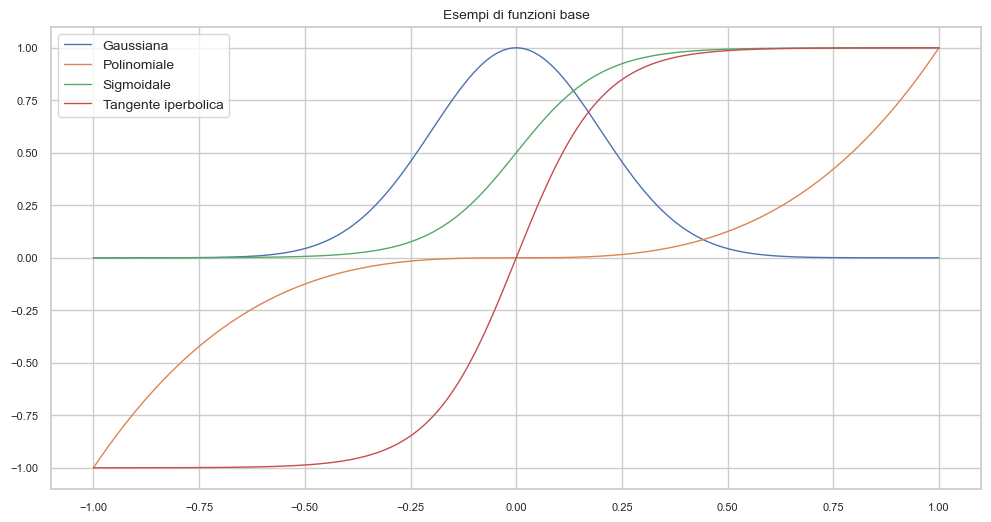

In [4]:
fig =plt.figure(figsize=(12,6))
x = np.linspace(-1,1,1000)
sns.lineplot(x=np.ravel(x), y=np.ravel(partial(gaussian_basis_function, **{'mu':0, 'sigma':0.2})(x)), linewidth=1, label='Gaussiana')
sns.lineplot(x=np.ravel(x), y=np.ravel(partial(polynomial_basis_function, **{'power':3})(x)), linewidth=1, label='Polinomiale')
sns.lineplot(x=np.ravel(x), y=np.ravel(partial(sigmoid_basis_function, **{'mu':0, 'sigma':.1})(x)), linewidth=1, label='Sigmoidale')
sns.lineplot(x=np.ravel(x), y=np.ravel(partial(tanh_basis_function, **{'mu':0, 'sigma':.1})(x)), linewidth=1, label='Tangente iperbolica')
plt.legend()
plt.title('Esempi di funzioni base')
plt.show()

### Dataset considerati

Gli esempi seguenti usano $n$ osservazioni scalari $x_i$, raccolte in una matrice (vettore colonna) $\mathbf{X}$ di dimensione $n\times1$. I target sono generati da due funzioni, `f` e `g`, che aggiungono rumore gaussiano di varianza specificata dal parametro `noise_variance`: `f` genera campioni rumorosi di una **retta**, $t=-0.3+0.5x+\varepsilon$ (la stessa dell'esempio di aggiornamento sequenziale delle note), mentre `g` genera campioni rumorosi di una **sinusoide**, $t=0.5+\sin(2\pi x)+\varepsilon$.

In entrambi i casi il rumore è additivo e gaussiano, $\varepsilon\sim\mathcal{N}(0,\beta^{-1})$: è il modello probabilistico delle note, in cui $\beta$ è la **precisione** del rumore.

In [5]:
#valori parametri per la funzione f
f_w0 = -0.3
f_w1 =  0.5

def f(X, noise_variance):
    #Funzione lineare con rumore gaussiano additivo
    return f_w0+f_w1*X+noise(X.shape, noise_variance)

def g(X, noise_variance):
    #Funzione sinusoidale con rumore gaussiano additivo
    return 0.5+np.sin(2*np.pi*X)+noise(X.shape, noise_variance)

def noise(size, variance):
    return np.random.normal(scale=np.sqrt(variance), size=size)

Generiamo $n=50$ valori di $x$ uniformemente in $[-1,1]$ e i corrispondenti target, con precisione del rumore $\beta=250$ (deviazione standard $1/\sqrt{250}\approx0.063$). La griglia `x` serve per disegnare le funzioni.

In [6]:
# calcola griglia di punti per la visualizzazione della funzione f
x = np.linspace(-1, 1, 1000).reshape(-1, 1)
# calcola valori assunti da f nei punti
y1 = f(x, noise_variance=0)

# estrae un campione di n elementi nel dataset
n = 50
X = np.random.rand(n, 1)*2-1

# calcola i corrispondenti valori target applicando la funzione f e aggiungendo rumore con precision beta
beta = 250.0
t1 = f(X, noise_variance=1/beta)

Il dataset generato dalla retta, e la retta stessa.

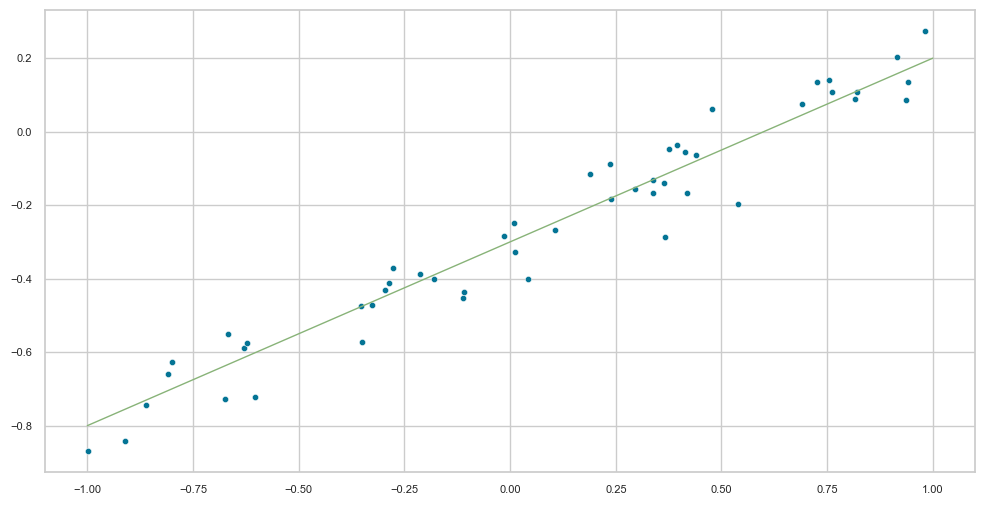

In [7]:
# plot della funzione f e del dataset
fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=1, color=colors[3])
plt.show()

Gli stessi input, con target generati dalla sinusoide.

In [8]:
#calcola i valori associati ai punti per mezzo della funzione g
t2 = g(X, noise_variance=1/beta)
y2 = g(x, noise_variance=0)

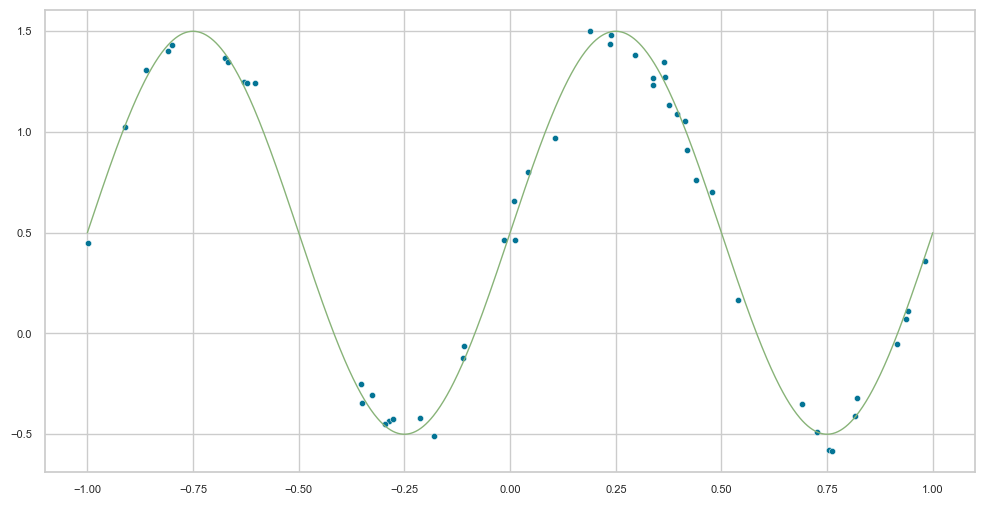

In [9]:
# plot della funzione g e del dataset
fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=1, color=colors[3])
plt.show()

### Funzioni base

Per il dataset generato dalla retta è sufficiente un modello lineare nell'input $x$: non serve trasformare $x$, il che equivale a usare la funzione base identità. Per il dataset sinusoidale servono invece funzioni base non lineari, ad esempio gaussiane, sigmoidali o polinomiali, che permettono al modello lineare nei parametri di rappresentare la relazione non lineare tra $x$ e $t$.

La matrice di design $\boldsymbol\Phi$ è calcolata dalle osservazioni $\mathbf{X}$ mediante la funzione `expand`. Come osservato sopra, la colonna costante $\phi_0(x)=1$ viene aggiunta solo nel caso della funzione base identità.

Le tre celle seguenti mostrano, per ciascuna famiglia, $5$ funzioni base sull'intervallo $[-1,1]$ e, con i punti colorati, i loro valori sugli elementi del dataset: ogni insieme di punti dello stesso colore è una colonna della matrice di design.

**Funzioni base gaussiane** con centri equispaziati in $[-1,1]$ e deviazione standard $0.1$: ogni elemento del dataset (punti in basso) attiva in modo significativo solo le funzioni base con centro vicino a esso.

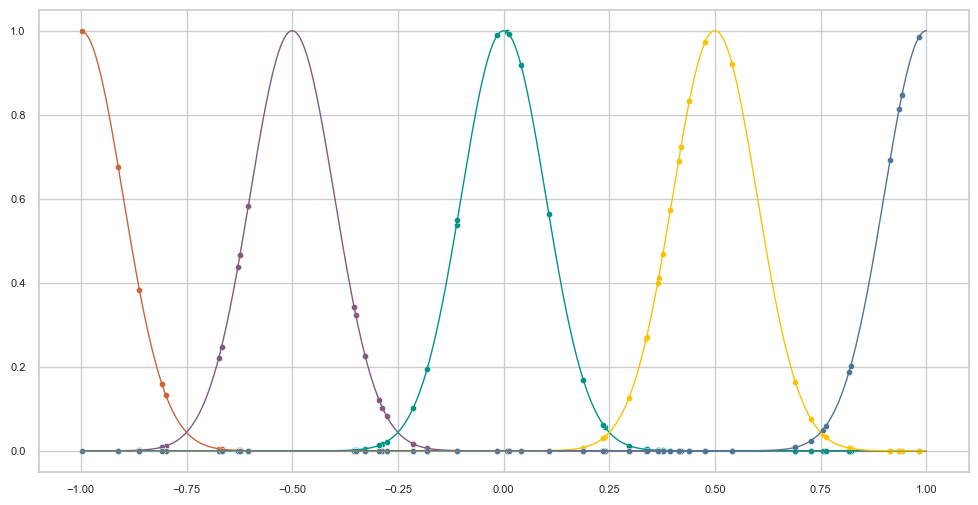

In [10]:
# funzioni base gaussiane 
# numero di funzioni base considerate
k = 5

# medie delle funzioni base, distribuite sull'intervallo considerato
mus = np.linspace(-1, 1, k)

fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(np.zeros_like(X)), s=20, color=colors[1])
for i, mu in enumerate(mus):  
    sns.lineplot(x=np.ravel(x), y=np.ravel(partial(gaussian_basis_function, **{'mu':mu, 'sigma':0.1})(x)), linewidth=1, color=colors[4+i])
    sns.scatterplot(x=np.ravel(X), y=np.ravel(partial(gaussian_basis_function, **{'mu':mu, 'sigma':0.1})(X)), s=20, color=colors[4+i])
plt.show()

**Funzioni base polinomiali** $1,x,x^2,x^3,x^4$: ogni elemento attiva tutte le funzioni base. Si noti che, in $[-1,1]$, le potenze di grado elevato sono molto simili tra loro (ad esempio $x^2$ e $x^4$), il che rende le colonne della matrice di design fortemente correlate e la matrice $\boldsymbol\Phi^T\boldsymbol\Phi$ mal condizionata per gradi elevati.

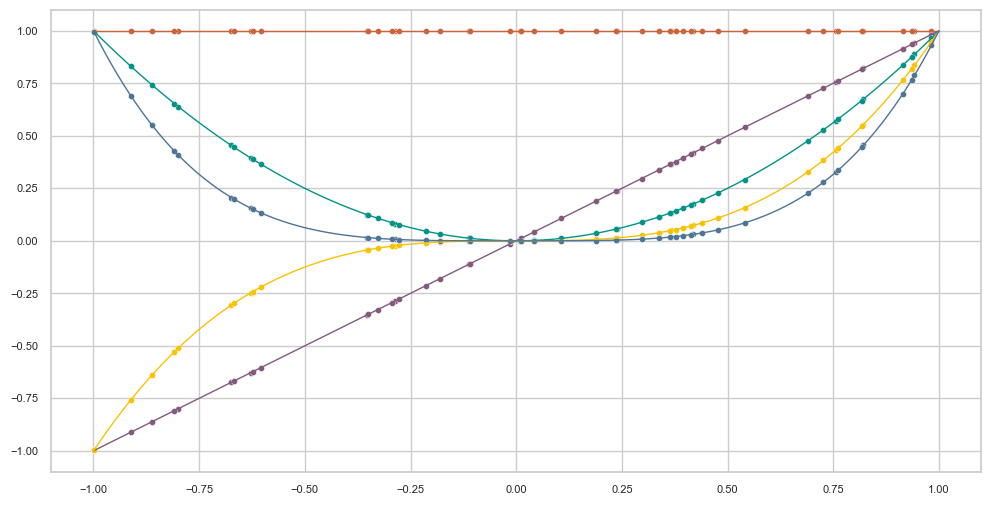

In [11]:
# funzioni base polinomiali 
k = 5

# grado delle funzioni base
powers = np.arange(k)

fig = plt.figure(figsize=(12,6))
for i, power in enumerate(powers):  
    sns.lineplot(x=np.ravel(x), y=np.ravel(partial(polynomial_basis_function, **{'power':power})(x)), linewidth=1, color=colors[4+i])
    sns.scatterplot(x=np.ravel(X), y=np.ravel(partial(polynomial_basis_function, **{'power':power})(X)), s=20, color=colors[4+i])
plt.show()

**Funzioni base sigmoidali** con centri equispaziati: gradini che passano da $0$ a $1$ in un intorno di ampiezza circa $0.1$ attorno al centro.

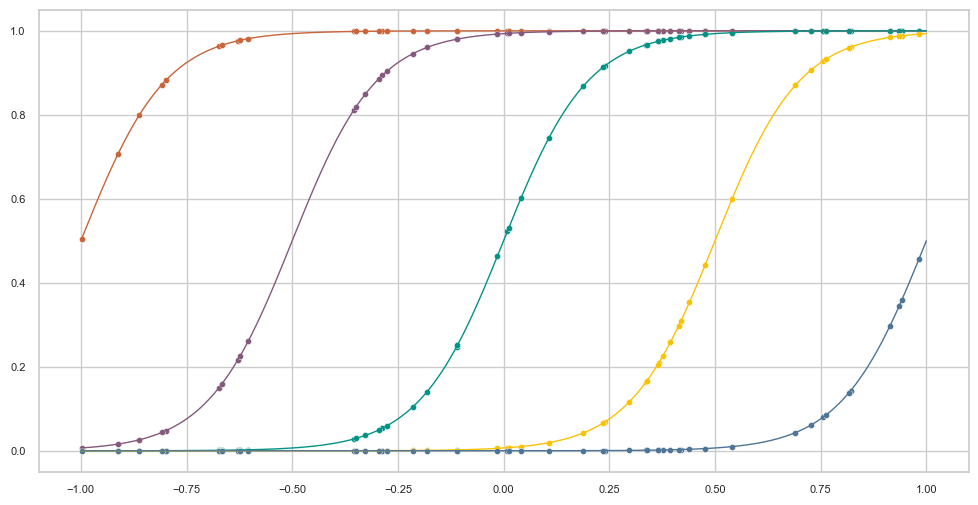

In [12]:
# funzioni base sigmoidali 
k = 5

# punti centrali delle funzioni base, distribuiti sull'intervallo considerato
mus = np.linspace(-1, 1, k)

fig = plt.figure(figsize=(12,6))
for i, mu in enumerate(mus):  
    sns.lineplot(x=np.ravel(x), y=np.ravel(partial(sigmoid_basis_function, **{'mu':mu, 'sigma':0.1})(x)), linewidth=1, color=colors[4+i])
    sns.scatterplot(x=np.ravel(X), y=np.ravel(partial(sigmoid_basis_function, **{'mu':mu, 'sigma':0.1})(X)), s=20, color=colors[4+i])
plt.show()

## Minimizzazione del rischio empirico

In questo approccio si definisce un insieme $\mathcal{H}$ di funzioni predittive e si sceglie quella che minimizza il **rischio empirico**
$$
\overline{\mathcal{R}}(h; \mathbf{X},\mathbf{t})=\frac{1}{n}\sum_{i=1}^nL(h(\mathbf{x}_i),t_i),\qquad
\hat{h}=\underset{h\in\mathcal{H}}{\mathrm{argmin}}\;\overline{\mathcal{R}}(h;\mathbf{X},\mathbf{t}),
$$
dove $L$ è una funzione di costo (_loss_) predefinita. Nel caso considerato:

- $\mathcal{H}$ è l'insieme delle funzioni lineari nei parametri, $h(\mathbf{x})=\boldsymbol\phi(\mathbf{x})^T\mathbf{w}$;
- la loss è quella **quadratica**, $(h(\mathbf{x})-t)^2$, il cui predittore ottimo è la media condizionata $\mathbb{E}[t\mid\mathbf{x}]$ (si vedano le note).

Il rischio empirico diventa quindi
$$
\overline{\mathcal{R}}(\mathbf{w}; \boldsymbol\Phi,\mathbf{t})=\frac{1}{n}\sum_{i=1}^n\left(\boldsymbol\phi(\mathbf{x}_i)^T\mathbf{w}-t_i\right)^2=
\frac{1}{n} \lVert \boldsymbol\Phi \mathbf{w} - \mathbf{t}\rVert^2,
$$
dove la **matrice di design** è
$$
\boldsymbol\Phi = 
\begin{pmatrix}
\phi_0(\mathbf{x}_1) &  \phi_1(\mathbf{x}_1) & \cdots & \phi_{m-1}(\mathbf{x}_1) \\ 
\vdots & \vdots & \ddots & \vdots \\
\phi_0(\mathbf{x}_n) &  \phi_1(\mathbf{x}_n) & \cdots & \phi_{m-1}(\mathbf{x}_n)
\end{pmatrix},
$$
e la minimizzazione si esegue nello spazio $\mathbb{R}^m$ dei parametri. Poiché il rischio empirico è una funzione quadratica convessa di $\mathbf{w}$, ha un unico minimo globale, che si ottiene annullando il gradiente: sono le **equazioni normali**
$$
\hat{\mathbf{w}}=(\boldsymbol\Phi^{T}\boldsymbol\Phi)^{-1}\boldsymbol\Phi^{T}\mathbf{t},
$$
valide quando $\boldsymbol\Phi^T\boldsymbol\Phi$ è invertibile, cioè quando nessuna funzione base è combinazione lineare delle altre sui dati. La funzione predittiva risultante è $\hat{h}(\mathbf{x})=\boldsymbol\phi(\mathbf{x})^T\hat{\mathbf{w}}$.

`erm` calcola i parametri ottimi con le equazioni normali. Dal punto di vista numerico, calcolare esplicitamente l'inversa è sconsigliato: `np.linalg.solve(Phi.T@Phi, Phi.T@t)` o `np.linalg.lstsq(Phi, t)` sono più stabili, soprattutto quando le funzioni base sono molto correlate. `predict` applica il modello appreso a nuovi elementi.

In [13]:
# minimizzazione del rischio empirico
def erm(X, t, args):
    Phi = expand(X, **args)
    return np.linalg.inv(Phi.T@Phi)@(Phi.T)@t

In [14]:
# funzione predittiva
def predict(x, w, args):
    y = expand(x, **args)@w
    if np.isscalar(x):
        return y.item()
    else:
        return y

Nel caso della retta, con la funzione base identità (`args = {}`), la retta stimata è molto vicina a quella vera: il modello ha la stessa forma della funzione che ha generato i dati, e $50$ punti con rumore modesto bastano a stimarne bene i due parametri.

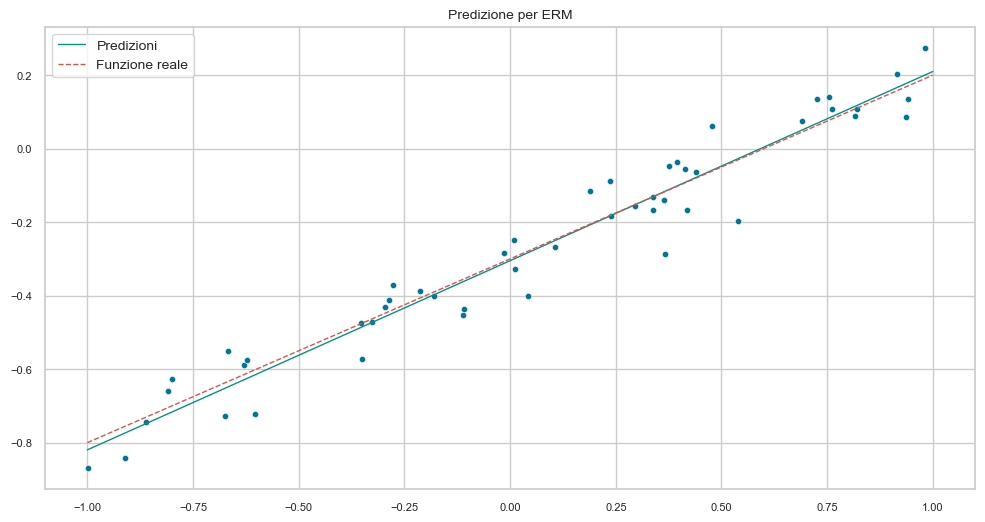

In [15]:
# caso funzione f lineare
args = {}

# calcola parametri che minimizzano il rischio empirico
w_star = erm(X, t1, args)

# visualizza funzione corretta f e valori predetti
fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict(x,w_star, args)), linewidth=1, color=colors[6], label='Predizioni')
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=1, color=colors[2], linestyle='dashed', label='Funzione reale')
plt.legend()
plt.title('Predizione per ERM')
plt.show()

Nel caso della sinusoide usiamo $10$ funzioni base con centri equispaziati in $[-1,1]$.

In [16]:
# caso funzione g sinusoidale
# numero di funzioni base
k = 10

# medie delle funzioni base gaussiane
mus = np.linspace(-1, 1, k)


La combinazione di gaussiane segue bene l'andamento della sinusoide; la sua forma dipende però dal numero e dalla larghezza delle funzioni base, ed è utile provare a cambiarle (ad esempio usando `gaussian_basis_function`, o aumentando `k`) per osservare l'insorgere di underfitting o di overfitting.

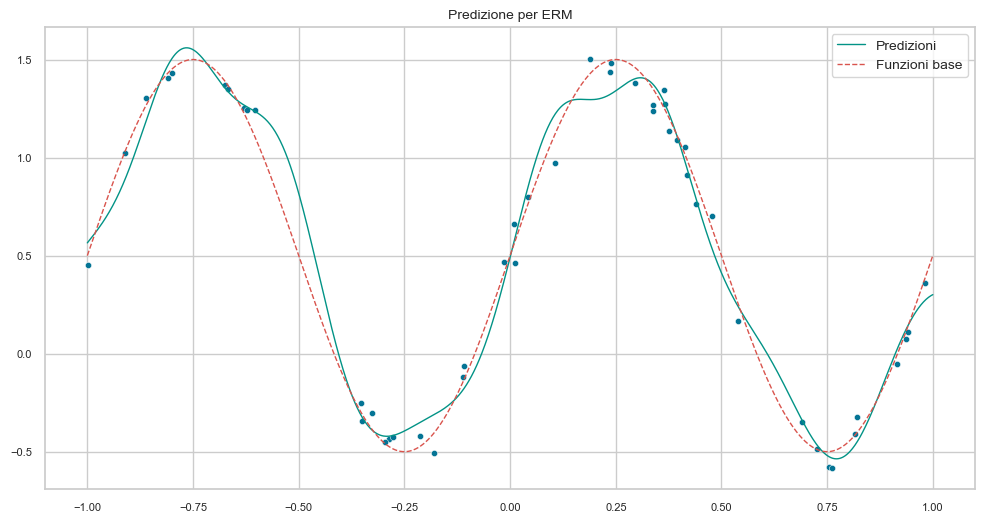

In [19]:
args = {'bf': gaussian_basis_function, 'bf_args_list':[{'mu':mu} for mu in mus]}

# minimizza il rischio empirico dopo applicazione delle funzioni base
w_star = erm(X, t2, args)

fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict(x,w_star, args)), linewidth=1, color=colors[6], label='Predizioni')
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=1, color=colors[2], linestyle='dashed', label='Funzioni base')
plt.legend()
plt.title('Predizione per ERM')
plt.show()

## Metodi probabilistici

In questo approccio si considera un modello probabilistico della relazione tra elementi e target. La distribuzione congiunta si fattorizza come $p(\mathbf{x}, t\mid\mathbf{w})=p(t\mid\mathbf{x},\mathbf{w})\,p(\mathbf{x})$, dove la distribuzione degli elementi $p(\mathbf{x})$ **non dipende dai parametri**: qualunque essa sia, non ha alcun ruolo nella loro stima, ed è sufficiente modellare la distribuzione condizionata $p(t\mid\mathbf{x},\mathbf{w})$ (si vedano le note).

Una prima idea consiste nel calcolare il valore $\hat{\mathbf{w}}_{ML}$ che massimizza la probabilità dei dati osservati. Assumendo che le coppie $(\mathbf{x}_i,t_i)$ siano indipendenti e identicamente distribuite,
$$
\hat{\mathbf{w}}_{ML} = \underset{\mathbf{w}}{\mathrm{argmax}}\; \prod_{i=1}^np(\mathbf{x}_i, t_i\mid\mathbf{w})= \underset{\mathbf{w}}{\mathrm{argmax}}\; \prod_{i=1}^np(t_i\mid\mathbf{x}_i,\mathbf{w})\,p(\mathbf{x}_i) = \underset{\mathbf{w}}{\mathrm{argmax}}\; \prod_{i=1}^np(t_i\mid\mathbf{x}_i,\mathbf{w}),
$$
e la distribuzione predittiva è $p(t\mid\mathbf{x}, \hat{\mathbf{w}}_{ML})$.

In generale, la distribuzione predittiva si ottiene marginalizzando i parametri,
$$
p(t\mid\mathbf{x}, \mathbf{X}, \mathbf{t}) = \int p(t\mid\mathbf{x}, \mathbf{w})\,p(\mathbf{w}\mid\mathbf{X}, \mathbf{t})\,d\mathbf{w},
$$
assumendo che $t$ sia indipendente da $\mathbf{X},\mathbf{t}$ dati $\mathbf{w}$ e $\mathbf{x}$, e che $\mathbf{w}$ sia indipendente da $\mathbf{x}$.

Usare un solo valore $\hat{\mathbf{w}}$ dei parametri equivale ad approssimare il posterior con una distribuzione concentrata in $\hat{\mathbf{w}}$, il che dà
$$
p(t\mid\mathbf{x}, \mathbf{X}, \mathbf{t}) \approx p(t\mid\mathbf{x}, \hat{\mathbf{w}}):
$$
si ignora così l'incertezza residua sui parametri.

Il modello probabilistico assume che il target sia il risultato di una funzione deterministica $h(\mathbf{x};\mathbf{w})$ più un rumore casuale, $t = h(\mathbf{x};\mathbf{w}) + \varepsilon$, con rumore gaussiano di media nulla e precisione $\beta$:
$$
p(t \mid \mathbf{x}, \mathbf{w}, \beta) = 
\mathcal{N}(t \mid h(\mathbf{x};\mathbf{w}), \beta^{-1}) =
\sqrt{\beta \over {2 \pi}} \exp\left(-{\beta \over 2} (t - h(\mathbf{x};\mathbf{w}))^2 \right).
$$
La media di questa distribuzione è la **funzione di regressione** $h(\mathbf{x};\mathbf{w})$.

## Verosimiglianza

Con le funzioni base, la probabilità dei target dati gli elementi è
$$
p(\mathbf{t} \mid \mathbf{X}, \mathbf{w}, \beta) = 
\prod_{i=1}^{n}{\mathcal{N}(t_i \mid \boldsymbol\phi(\mathbf{x}_i)^T\mathbf{w}, \beta^{-1})}.
$$
Vista come funzione di $\mathbf{w}$ e $\beta$, è la **verosimiglianza** (_likelihood_). Il suo logaritmo è
$$
\log p(\mathbf{t} \mid \mathbf{X}, \mathbf{w}, \beta) = 
{n \over 2} \log \beta - 
{n \over 2} \log {2 \pi} - 
\beta E_D(\mathbf{w}),\qquad
E_D(\mathbf{w}) = 
{1 \over 2} \sum_{i=1}^{n}(t_i - \boldsymbol\phi(\mathbf{x}_i)^T\mathbf{w})^2 = 
{1 \over 2} \lVert \mathbf{t} - \boldsymbol\Phi \mathbf{w} \rVert^2.
$$
Poiché il logaritmo è monotono, verosimiglianza e log-verosimiglianza hanno lo stesso massimo. $E_D(\mathbf{w})$, che deriva dall'esponente della gaussiana, è la somma dei quadrati dei residui.

## Massima verosimiglianza

Massimizzare la log-verosimiglianza rispetto a $\mathbf{w}$ equivale quindi a minimizzare il rischio empirico con loss quadratica: **i minimi quadrati sono la stima di massima verosimiglianza sotto rumore gaussiano**, e
$$
\mathbf{w}_{ML}=\left(\boldsymbol\Phi^T \boldsymbol\Phi\right)^{-1} \boldsymbol\Phi^T \mathbf{t}.
$$
Il modello probabilistico, però, permette di stimare anche l'entità del rumore: massimizzando rispetto a $\beta$ si ottiene
$$
\hat{\beta}^{-1}=\hat\sigma^2=\frac{1}{n}\sum_{i=1}^n\left(t_i-\boldsymbol\phi(\mathbf{x}_i)^T\mathbf{w}_{ML}\right)^2,
$$
la media dei quadrati dei residui. La predizione diventa una distribuzione, $\mathcal{N}(t\mid\boldsymbol\phi(\mathbf{x})^T\mathbf{w}_{ML},\hat\sigma^2)$, con un'incertezza costante su tutto il dominio.

La massima verosimiglianza può produrre un forte overfitting se modelli molto flessibili (ad esempio polinomi di grado elevato) sono stimati su pochi dati. Un rimedio diffuso è aggiungere un termine di regolarizzazione, che, come vedremo, emerge in modo naturale dall'approccio bayesiano, introducendo una distribuzione a priori sui parametri.

`mle` coincide con `erm`: è la stessa formula, giustificata in modo diverso. `std_ml` calcola la stima di massima verosimiglianza della deviazione standard del rumore, cioè la radice della media dei quadrati dei residui.

In [20]:
# massimizzazione della log-verosimiglianza rispetto ai parametri
def mle(X, t, args):
    Phi = expand(X, **args)
    return np.linalg.inv(Phi.T@Phi)@(Phi.T)@t

In [21]:
# massimizzazione della log-verosimiglianza rispetto alla deviazione standard
def std_ml(X, t, w, args):
    Phi = expand(X, **args)
    y = Phi@w
    return np.sqrt(np.mean((t-y)**2))

In [22]:
# funzione lineare
# calcolo dei parametri e della deviazione standard di massima verosimiglianza per il dataset considerato
args1 = {}
w_ML = mle(X, t1, args1)
std_ML = std_ml(X, t1, w_ML, args1)

La retta stimata e la banda a una deviazione standard $\pm\hat\sigma$. La banda ha **larghezza costante**: la massima verosimiglianza tiene conto solo del rumore dei dati, non dell'incertezza sui parametri, che è maggiore lontano dai punti osservati.

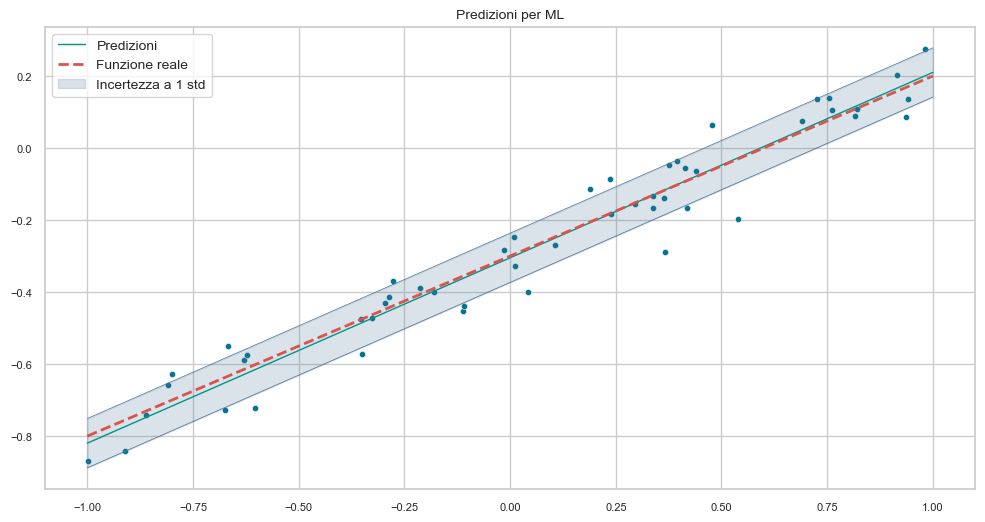

In [23]:
fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
pred = predict(x,w_ML, args1)
sns.lineplot(x=np.ravel(x), y=np.ravel(pred), linewidth=1, color=colors[6], label='Predizioni')
sns.lineplot(x=np.ravel(x), y=np.ravel(pred-std_ML), linewidth=.5, color=colors[8])
sns.lineplot(x=np.ravel(x), y=np.ravel(pred+std_ML), linewidth=.5, color=colors[8])
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Funzione reale')
plt.fill_between(x.ravel(), (pred-std_ML).ravel(), (pred+std_ML).ravel(), color=colors[8], alpha=.2, label='Incertezza a 1 std')
plt.legend()
plt.title('Predizioni per ML')
plt.show()

Per la sinusoide usiamo questa volta $10$ funzioni base **gaussiane** con centri equispaziati e deviazione standard predefinita $0.1$.

In [24]:
# funzione sinusoidale
# calcolo dei parametri e della deviazione standard di massima verosimiglianza per il dataset considerato, con applicazione di funzioni base
k = 10
mus = np.linspace(-1, 1, k)
args2 = {'bf': gaussian_basis_function, 'bf_args_list':[{'mu':mu} for mu in mus]}
w_ML = mle(X, t2, args2)
std_ML = std_ml(X, t2, w_ML, args2)

Anche qui la banda di incertezza ha larghezza costante, pari a $\pm\hat\sigma$. Poiché $\hat\sigma$ è calcolata sui residui del training set, è una stima ottimistica del rumore quando il modello è molto flessibile (come visto nel notebook sull'overfitting).

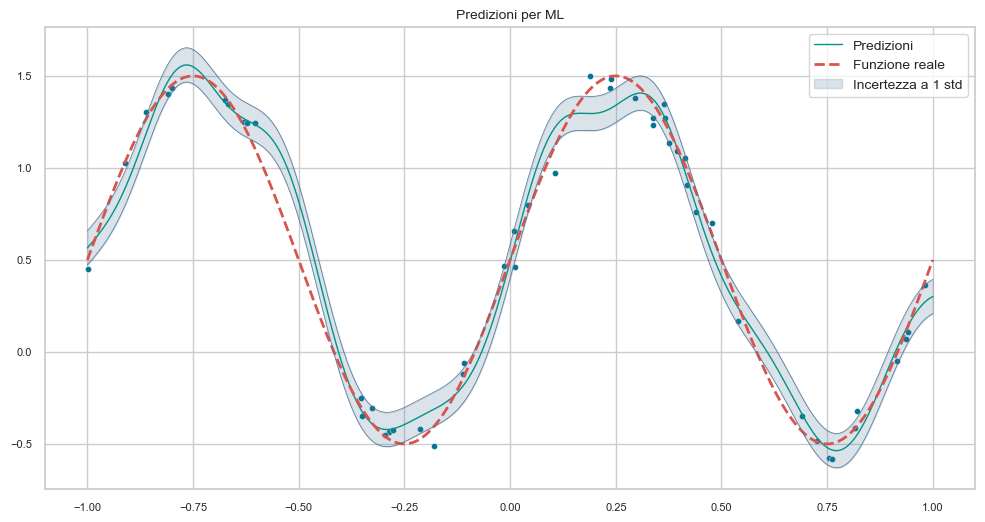

In [25]:

fig = plt.figure(figsize=(12,6))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
pred = predict(x,w_ML, args2)
sns.lineplot(x=np.ravel(x), y=np.ravel(pred), linewidth=1, color=colors[6], label='Predizioni')
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=2, color=colors[2], linestyle='dashed', label='Funzione reale')
sns.lineplot(x=np.ravel(x), y=np.ravel(pred-std_ML), linewidth=.5, color=colors[8])
sns.lineplot(x=np.ravel(x), y=np.ravel(pred+std_ML), linewidth=.5, color=colors[8])
plt.fill_between(x.T.squeeze(), (pred-std_ML).ravel(), (pred+std_ML).ravel(), color=colors[8], alpha=.2, label='Incertezza a 1 std')
plt.legend()
plt.title('Predizioni per ML')
plt.show()

## Approccio bayesiano

### Distribuzioni a priori e a posteriori

Nel trattamento bayesiano i parametri $\mathbf{w}$ sono variabili casuali, con una distribuzione **a priori** che esprime ciò che si crede di essi prima di osservare i dati. Per semplicità si usa una gaussiana isotropa con media nulla,
$$
p(\mathbf{w} \mid \alpha) = \mathcal{N}(\mathbf{w} \mid \mathbf{0}, \alpha^{-1}\mathbf{I}),
$$
la cui matrice di covarianza è diagonale con tutte le varianze pari a $\alpha^{-1}$: $\alpha$ è la **precisione** del prior. La media nulla esprime l'assenza di preferenze per il segno dei parametri, e, insieme a una precisione elevata, una preferenza per valori piccoli.

`plot_bivariate_gaussian` disegna la densità di una gaussiana bidimensionale su una griglia del quadrato $[-1,1]^2$: la useremo per visualizzare prior e posterior nel piano dei parametri $(w_0,w_1)$ del modello lineare.

In [26]:
# visualizza una gaussiana bivariata
def plot_bivariate_gaussian(mean, cov, resolution = 100):
    grid_x = grid_y = np.linspace(-1, 1, resolution)
    grid_flat = np.dstack(np.meshgrid(grid_x, grid_y)).reshape(-1, 2)
    densities = stats.multivariate_normal.pdf(grid_flat, mean=mean.ravel(), cov=cov).reshape(resolution, resolution)
    plt.imshow(densities, origin='lower', extent=(-1, 1, -1, 1))
    plt.xticks([-1,-.5,0,.5,1])
    plt.yticks([-1,-.5,0,.5,1])
    plt.xlabel('$w_0$')
    plt.ylabel('$w_1$')

Prior con precisione $\alpha=10$, cioè deviazione standard $1/\sqrt{10}\approx0.32$ per ciascun parametro.

In [27]:
# calcola i parametri della distribuzione a priori
alpha = 10
cov = 1/alpha*np.eye(2, dtype=int)
mean = np.zeros(2)

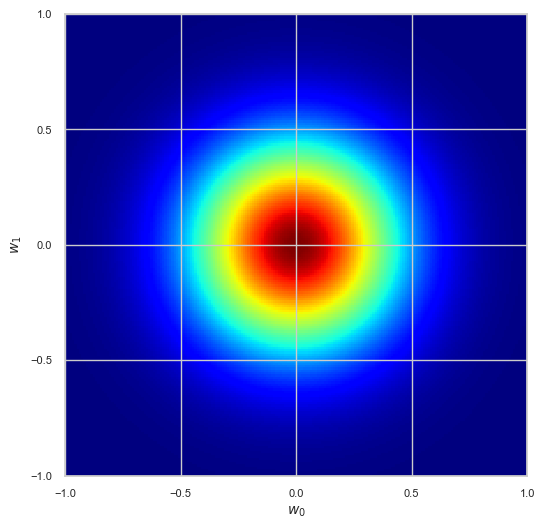

In [28]:
plt.figure(figsize=(6,6))
plot_bivariate_gaussian(mean, cov, 200)
plt.show()

Il prior è **coniugato** alla verosimiglianza gaussiana: il posterior ha la stessa forma funzionale, ed è quindi gaussiano,
$$
p(\mathbf{w} \mid \mathbf{X}, \mathbf{t}, \alpha, \beta) = \mathcal{N}(\mathbf{w} \mid \mathbf{m}_p, \boldsymbol\Sigma_p),
\qquad
\mathbf{m}_p = \beta\, \boldsymbol\Sigma_p \boldsymbol\Phi^T \mathbf{t},
\qquad
\boldsymbol\Sigma_p = \left(\alpha\mathbf{I} + \beta \boldsymbol\Phi^T \boldsymbol\Phi\right)^{-1}.
$$
La precisione del posterior, $\boldsymbol\Sigma_p^{-1}$, è la somma della precisione del prior e di quella fornita dai dati, $\beta\boldsymbol\Phi^T\boldsymbol\Phi$, che cresce con il numero di elementi osservati.

Assumiamo per ora che $\alpha$ e $\beta$ siano noti. Poiché il posterior è proporzionale al prodotto di verosimiglianza e prior, il suo logaritmo è, a meno di una costante,
$$
\log p(\mathbf{w} \mid \mathbf{X}, \mathbf{t}, \alpha, \beta) = 
-\beta E_D(\mathbf{w}) - \alpha E_W(\mathbf{w}) + \mathrm{cost.},\qquad
E_W(\mathbf{w}) = {1 \over 2} \mathbf{w}^T \mathbf{w}.
$$
Massimizzarlo fornisce la stima **maximum a posteriori** (MAP), ed equivale a minimizzare la somma di $E_D$ e di un termine di regolarizzazione quadratico: è la **ridge regression** (o regolarizzazione $L_2$, o *weight decay*), con coefficiente di regolarizzazione $\lambda=\alpha/\beta$. Poiché il posterior è gaussiano, la sua moda coincide con la media:
$$
\mathbf{w}_{MAP}=\mathbf{m}_p=\left(\frac\alpha\beta\mathbf{I} + \boldsymbol\Phi^T \boldsymbol\Phi\right)^{-1} \boldsymbol\Phi^T \mathbf{t}.
$$

### Distribuzione predittiva

La predizione pienamente bayesiana usa l'intero posterior:
$$
p(t \mid \mathbf{x}, \mathbf{X}, \mathbf{t}, \alpha, \beta) = 
\int{p(t \mid \mathbf{x}, \mathbf{w}, \beta)\, p(\mathbf{w} \mid \mathbf{X}, \mathbf{t}, \alpha, \beta)\, d\mathbf{w}},
$$
cioè media le predizioni di tutti i valori dei parametri, pesandole con la loro probabilità a posteriori. Nel caso gaussiano anche la distribuzione predittiva è gaussiana,
$$
p(t \mid \mathbf{x}, \mathbf{X}, \mathbf{t}, \alpha, \beta) = 
\mathcal{N}\bigl(t \mid \boldsymbol\phi(\mathbf{x})^T\mathbf{m}_p , \sigma^2(\mathbf{x})\bigr),\qquad
\sigma^2(\mathbf{x}) = {1 \over \beta} + \boldsymbol\phi(\mathbf{x})^T \boldsymbol\Sigma_p \boldsymbol\phi(\mathbf{x}).
$$
Il primo termine della varianza è il rumore intrinseco nei dati (incertezza **aleatoria**), il secondo l'incertezza sui parametri (incertezza **epistemica**), che diminuisce con il numero di dati ed è minore vicino ai punti osservati.

`mpe` calcola media e covarianza del posterior (il nome ricorda che la media è anche la stima MAP); `posterior_predictive` calcola media e varianza della distribuzione predittiva in un insieme di punti.

In [29]:
# massimizzazione della distribuzione a posteriori rispetto ai parametri
def mpe(X, t, alpha, beta, args):
    Phi = expand(X, **args)
    Sigma_p_inv = alpha * np.eye(Phi.shape[1]) + beta * Phi.T@Phi
    Sigma_p = np.linalg.inv(Sigma_p_inv)
    m_p = beta * Sigma_p@(Phi.T)@t
    return m_p, Sigma_p

In [30]:
def posterior_predictive(X, m_p, Sigma_p, beta, args):
    Phi = expand(X, **args)
    y = Phi@m_p
    y_var = 1 / beta + np.diag(Phi@Sigma_p@Phi.T).reshape(-1,1)
    return y, y_var

### Esempio: la retta

Usiamo solo $5$ elementi scelti a caso dal dataset (evidenziati), per rendere visibile l'incertezza. I tre pannelli mostrano:

1. il **posterior** nel piano $(w_0,w_1)$, concentrato attorno ai valori veri $(-0.3,0.5)$ ma ancora con una certa dispersione;
2. $7$ **rette campionate** dal posterior, tutte vicine ai punti usati e più disperse lontano da essi;
3. la **distribuzione predittiva**: la media e la banda a una deviazione standard, più stretta nella regione dei punti osservati e più larga ai bordi, a differenza della banda costante della massima verosimiglianza.

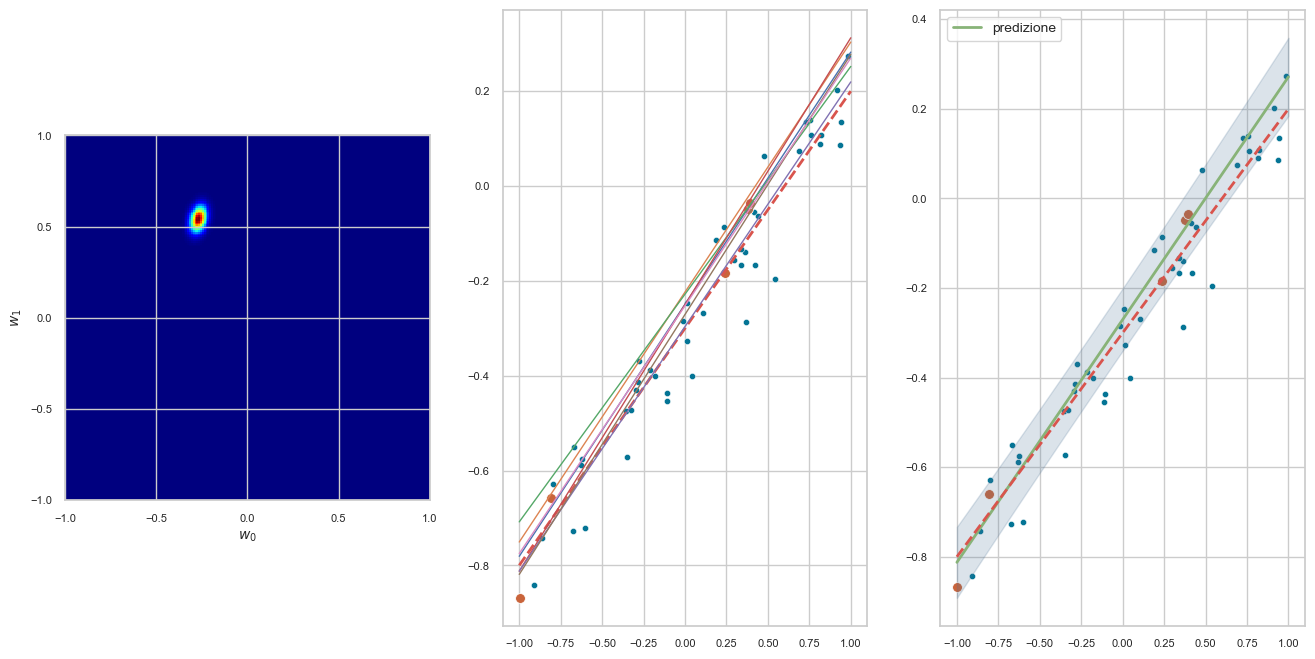

In [31]:
# funzione lineare
# numero di esempi considerati per il calcolo della distribuzione a posteriori
nexamples = 5
# numero di modelli campionati dalla distribuzione a posteriori
nsamples = 7
# determina l'insieme di esempi considerati
idx = random.sample(range(X.shape[0]), nexamples)
X_s, t_s = X[idx], t1[idx]
# applica funzioni base (identità in questo caso)
args1 = {}
# calcola distribuzione a posteriori dei parametri
m_p, Sigma_p = mpe(X_s, t_s, alpha, beta, args1)
# estrae insieme di modelli predittivi
w_samples = np.random.multivariate_normal(m_p.ravel(), Sigma_p, nsamples)
# calcola predizioni per tutti i punti della griglia
pred, sigma_2 = posterior_predictive(x, m_p, Sigma_p, beta, args1)

fig = plt.figure(figsize=(16,8))
# plot della distribuzione a posteriori (bivariata)
plt.subplot(1,3,1)
plot_bivariate_gaussian(m_p, Sigma_p, 200)
plt.subplot(1,3,2)
# punti nel dataset
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
# punti effettivamente considerati 
sns.scatterplot(x=np.ravel(X_s), y=np.ravel(t_s), s=50, color=colors[4])
# funzione reale
sns.lineplot(x=np.ravel(x), y=np.ravel(y1.ravel()), linestyle='dashed', linewidth=2, color=colors[2])
# funzioni predittive da sampling della distribuzione a posteriori
for w in w_samples:
    sns.lineplot(x=np.ravel(x), y=np.ravel(np.dot(expand(x, **args1), w.reshape(-1,1))), linewidth=1)
plt.subplot(1,3,3)
sns.lineplot(x=np.ravel(x), y=np.ravel(pred), color=colors[3], label='predizione', linewidth=2)
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.scatterplot(x=np.ravel(X_s), y=np.ravel(t_s), s=50, color=colors[4])
# plot distribuzione predittiva
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linestyle='dashed', linewidth=2, color=colors[2])
plt.fill_between(x.ravel(), pred.ravel()-np.sqrt(sigma_2.ravel()), pred.ravel()+np.sqrt(sigma_2.ravel()), color=colors[8], alpha=.2)
plt.show()

### Esempio: la sinusoide

Con $8$ elementi e $10$ funzioni base sigmoidali: il modello ha più parametri che dati, e senza prior il problema sarebbe sottodeterminato. Il prior rende il posterior ben definito. Le curve campionate concordano vicino agli elementi osservati e divergono tra di essi, e la banda predittiva è corrispondentemente stretta o larga. (Il posterior, a $10$ dimensioni, non viene disegnato.)

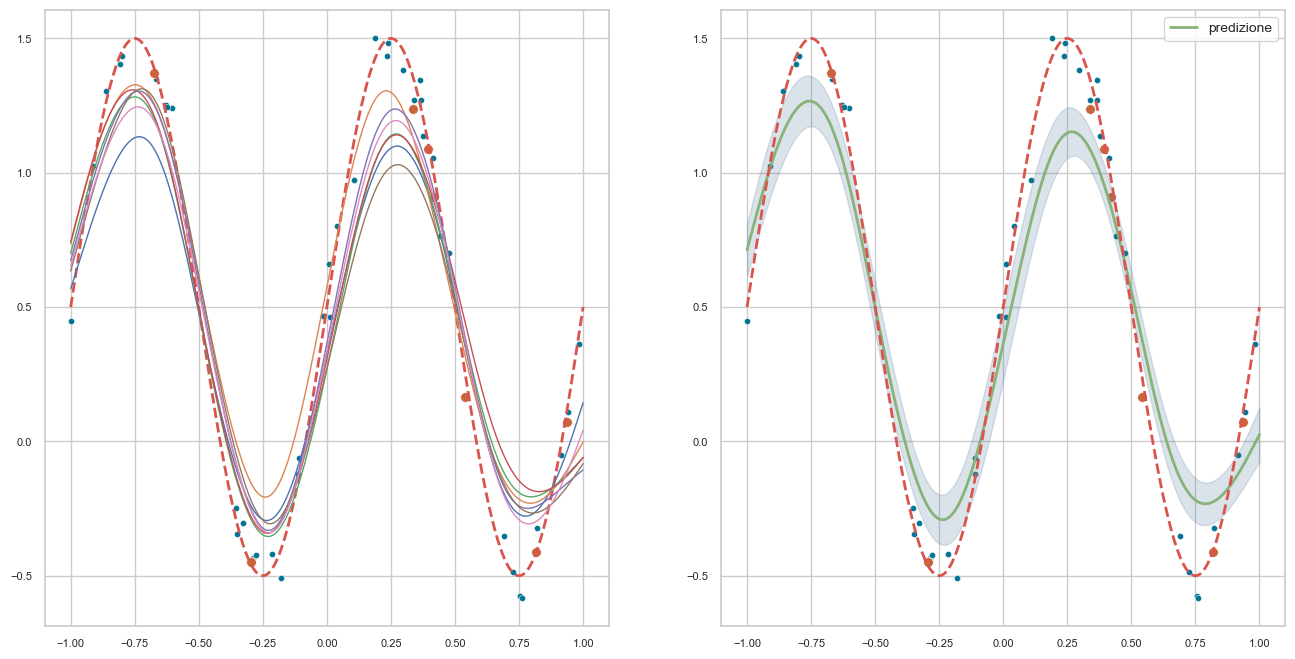

In [33]:
# funzione sinusoidale
# numero di esempi considerati per il calcolo della distribuzione a posteriori
nexamples = 8
# numero di modelli campionati dalla distribuzione a posteriori
nsamples = 7
# determina l'insieme di esempi considerati
# determina l'insieme di esempi considerati
idx = random.sample(range(X.shape[0]), nexamples)
X_s, t_s = X[idx], t2[idx]
# applica funzioni base (sigmoidali in questo caso)
k = 10
mus = np.linspace(-1, 1, k)
args2 = {'bf': sigmoid_basis_function, 'bf_args_list':[{'mu':mu} for mu in mus]}

# calcola distribuzione a posteriori dei parametri
m_p, Sigma_p = mpe(X_s, t_s, alpha, beta, args2)
# estrae insieme di modelli predittivi
w_samples = np.random.multivariate_normal(m_p.ravel(), Sigma_p, nsamples)
# calcola predizioni per tutti i punti della griglia
pred, sigma_2 = posterior_predictive(x, m_p, Sigma_p, beta, args2)

fig = plt.figure(figsize=(16,8))
# plot della distribuzione a posteriori (bivariata)
plt.subplot(1,2,1)
# punti nel dataset
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
# punti effettivamente considerati 
sns.scatterplot(x=np.ravel(X_s), y=np.ravel(t_s), s=50, color=colors[4])
# funzione reale
sns.lineplot(x=np.ravel(x), y=np.ravel(y2.ravel()), linestyle='dashed', linewidth=2, color=colors[2])
# funzioni predittive da sampling della distribuzione a posteriori
for w in w_samples:
    sns.lineplot(x=np.ravel(x), y=np.ravel(np.dot(expand(x, **args2), w.reshape(-1,1))), linewidth=1)
plt.subplot(1,2,2)
sns.lineplot(x=np.ravel(x), y=np.ravel(pred), color=colors[3], label='predizione', linewidth=2)
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.scatterplot(x=np.ravel(X_s), y=np.ravel(t_s), s=50, color=colors[4])
# plot distribuzione predittiva
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linestyle='dashed', linewidth=2, color=colors[2])
plt.fill_between(x.ravel(), pred.ravel()-np.sqrt(sigma_2.ravel()), pred.ravel()+np.sqrt(sigma_2.ravel()), color=colors[8], alpha=.2)
plt.show()

Al crescere del numero di elementi considerati, la varianza, e quindi l'incertezza, delle predizioni diminuisce, e le regioni con meno osservazioni presentano un'incertezza maggiore. È utile rieseguire le due celle precedenti con valori diversi di `nexamples` (ad esempio $2$, $5$, $20$, $50$): con pochi elementi il prior domina e le curve campionate sono molto diverse; con molti elementi il posterior si concentra, le curve diventano indistinguibili e la banda si riduce all'incertezza aleatoria $1/\sqrt\beta$.

### Verosimiglianza marginale ed evidenza

Un trattamento pienamente bayesiano richiederebbe di introdurre distribuzioni a priori anche per gli iperparametri $\alpha$ e $\beta$, e di integrarli insieme ai parametri:
$$
p(t \mid \mathbf{x}, \mathbf{X}, \mathbf{t}) = 
\int{p(t \mid \mathbf{x}, \mathbf{w}, \beta)\, p(\mathbf{w} \mid \mathbf{X}, \mathbf{t}, \alpha, \beta)\, p(\alpha,\beta\mid\mathbf{X},\mathbf{t})\,d\mathbf{w}\,d\alpha\,d\beta}.
$$
Questo integrale non è calcolabile analiticamente, e richiede metodi approssimati (approssimazione di Laplace, inferenza variazionale, Monte Carlo).

In alternativa, $\alpha$ e $\beta$ possono essere stimati massimizzando la **verosimiglianza marginale**, ottenuta integrando i parametri $\mathbf{w}$:
$$
p(\mathbf{t} \mid \mathbf{X}, \alpha, \beta) =
\int{p(\mathbf{t} \mid \mathbf{X}, \mathbf{w}, \beta)\, p(\mathbf{w} \mid \alpha)\, d\mathbf{w}}.
$$
Poiché $p(\alpha, \beta\mid\mathbf{X}, \mathbf{t})\propto p(\mathbf{t} \mid \mathbf{X}, \alpha, \beta)\, p(\alpha, \beta)$, se il prior sugli iperparametri è uniforme due coppie di valori si confrontano confrontando le verosimiglianze marginali,
$$
\frac{p(\alpha_1, \beta_1\mid\mathbf{X}, \mathbf{t})}{p(\alpha_2, \beta_2\mid\mathbf{X}, \mathbf{t})}=\frac{p(\mathbf{t}\mid\mathbf{X}, \alpha_1, \beta_1)}{p(\mathbf{t}\mid\mathbf{X}, \alpha_2, \beta_2)},
$$
un rapporto detto **fattore di Bayes**. La stessa quantità $p(\mathbf{t} \mid \mathbf{X}, \alpha, \beta)$ compare al denominatore della regola di Bayes,
$$
p(\mathbf{w} \mid \mathbf{X}, \mathbf{t}, \alpha, \beta) = 
{p(\mathbf{t} \mid \mathbf{X}, \mathbf{w}, \beta)\, p(\mathbf{w} \mid \alpha) \over p(\mathbf{t} \mid \mathbf{X}, \alpha, \beta)},
$$
dove svolge il ruolo di **evidenza**: misura quanto bene il modello, con quegli iperparametri, spiega i dati una volta mediati i parametri secondo il prior. Poiché i parametri sono integrati, modelli di complessità diversa diventano direttamente confrontabili sul training set, senza un validation set.

Per prior e verosimiglianza gaussiani, il logaritmo dell'evidenza è
$$
\log p(\mathbf{t} \mid \mathbf{X}, \alpha, \beta) = \frac{m}{2}\log\alpha + \frac{n}{2}\log\beta -
E(\mathbf{m}_p)-\frac{1}{2}\log\lvert\boldsymbol\Sigma_p^{-1}\rvert - \frac{n}{2}\log(2\pi),
\qquad
E(\mathbf{m}_p) = \frac{\beta}{2} \lVert \mathbf{t} - \boldsymbol\Phi \mathbf{m}_p \rVert^2 +
\frac{\alpha}{2} \lVert\mathbf{m}_p\rVert^2,
$$
dove $m$ è il numero di parametri. Il termine $-E(\mathbf{m}_p)$ misura l'adattamento ai dati; i termini $\frac m2\log\alpha-\frac12\log|\boldsymbol\Sigma_p^{-1}|$ agiscono come una **penalità di Occam**, che penalizza i modelli che, per adattarsi ai dati, devono concentrarsi in una piccola regione del proprio spazio dei parametri.

`log_marginal_likelihood` implementa la formula precedente (il fattore $\frac12$ è applicato alla fine a tutti i termini).

In [34]:
# calcola la verosimiglianza marginale
def log_marginal_likelihood(X, t, alpha, beta, args):
    Phi = expand(X, **args)
    n, m = Phi.shape
    m_p, Sigma_p = mpe(X, t, alpha, beta, args)
    Sigma_p_inv = np.linalg.inv(Sigma_p)
    E_D = beta * np.sum((t - Phi@m_p) ** 2)
    E_W = alpha * np.sum(m_p ** 2)
    score = m*np.log(alpha) + n*np.log(beta) - E_D - E_W - np.log(np.linalg.det(Sigma_p_inv)) - n*np.log(2*np.pi)
    return 0.5 * score

#### Massimizzazione della verosimiglianza marginale

L'approccio che stima $\alpha$ e $\beta$ massimizzando l'evidenza prende il nome di **empirical Bayes**, o *evidence framework*. Si può mostrare che è una buona approssimazione dell'approccio pienamente bayesiano quando il posterior di $\alpha$ e $\beta$ è fortemente concentrato attorno alla moda e il loro prior è quasi uniforme.

Integrare i parametri permette di stimare i valori migliori di $\alpha$ e $\beta$, e quindi del coefficiente di regolarizzazione $\alpha/\beta$, usando solo il training set.

Come primo esempio, l'evidenza viene usata per **scegliere il modello**: confrontiamo modelli con un numero diverso di funzioni base gaussiane equidistanti, da $1$ a $10$, sullo stesso dataset di $20$ punti della sinusoide in $[0,1]$, con $\alpha$ e $\beta$ fissati.

Si noti che questa cella **ridefinisce** $\alpha$ e $\beta$ ($\beta=1/0.3^2$, $\alpha=0.005$), che restano in uso nelle celle successive.

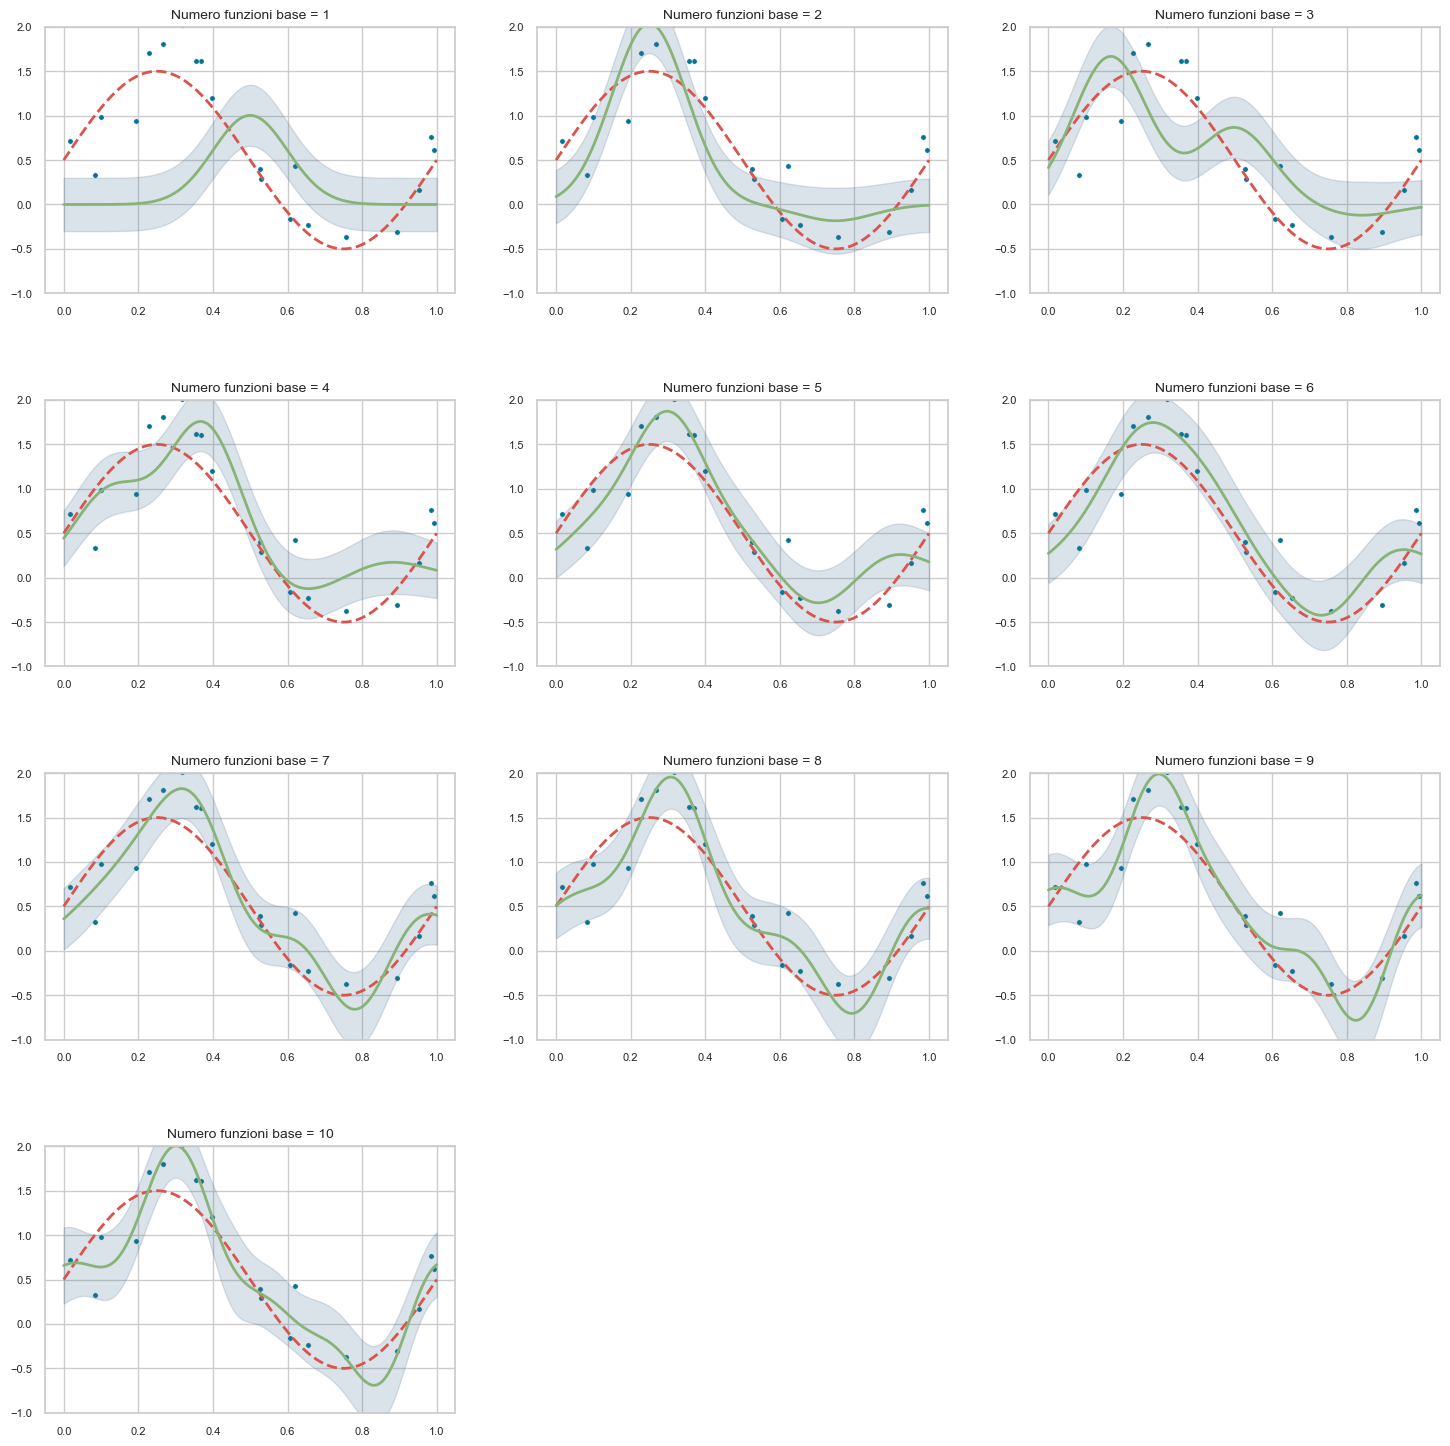

In [35]:
beta = 1/(0.3 ** 2)
alpha = 0.005

nexamples = 20

x0 = np.linspace(0, 1, 1000).reshape(-1, 1)
y0 = g(x0, noise_variance=0).T

X_ = np.random.rand(50, 1)
X0 = X_[:nexamples]
t0 = g(X0, noise_variance=1/beta)

degree = 9
degrees = range(degree + 1)

m = 10
rows = int(m/3)+1

plt.figure(figsize=(18, 18))
plt.subplots_adjust(hspace=0.4)
for d in range(1, m+1):
    mus = np.linspace(x0[0], x0[-1], d+1)
    args0 = {'bf': gaussian_basis_function, 'bf_args_list':[{'mu':mus[k]+.5*(mus[k+1]-mus[k])} for k in range(len(mus)-1)]}
    m_p, Sigma_p = mpe(X0, t0, alpha, beta, args0)
    y, y_var = posterior_predictive(x0, m_p, Sigma_p, beta, args0)
    plt.subplot(rows, 3, d)
    sns.scatterplot(x=np.ravel(X0), y=np.ravel(t0), s=15, color=colors[1])
    sns.lineplot(x=np.ravel(x0), y=np.ravel(y0.ravel()), color=colors[2], linestyle='dashed')
    sns.lineplot(x=np.ravel(x0), y=np.ravel(y), color=colors[3])
    plt.fill_between(x0.ravel(),y.ravel()-np.sqrt(y_var.ravel()),y.ravel()+np.sqrt(y_var.ravel()), color=colors[8], alpha=.2)
    plt.title(f'Numero funzioni base = {d}')
    plt.ylim(-1.0, 2.0)

Il grafico riporta la log-verosimiglianza marginale in funzione del numero di funzioni base. Con poche funzioni base il modello non riesce ad adattarsi ai dati e l'evidenza è bassa; con troppe, il modello è più flessibile del necessario e la penalità di Occam fa diminuire l'evidenza. Il massimo, indicato dalla linea tratteggiata, corrisponde al modello che bilancia adattamento e complessità, ed è scelto **senza usare dati di validazione**: è il compromesso tra underfitting e overfitting già visto con il test set, ottenuto qui dal solo training set.

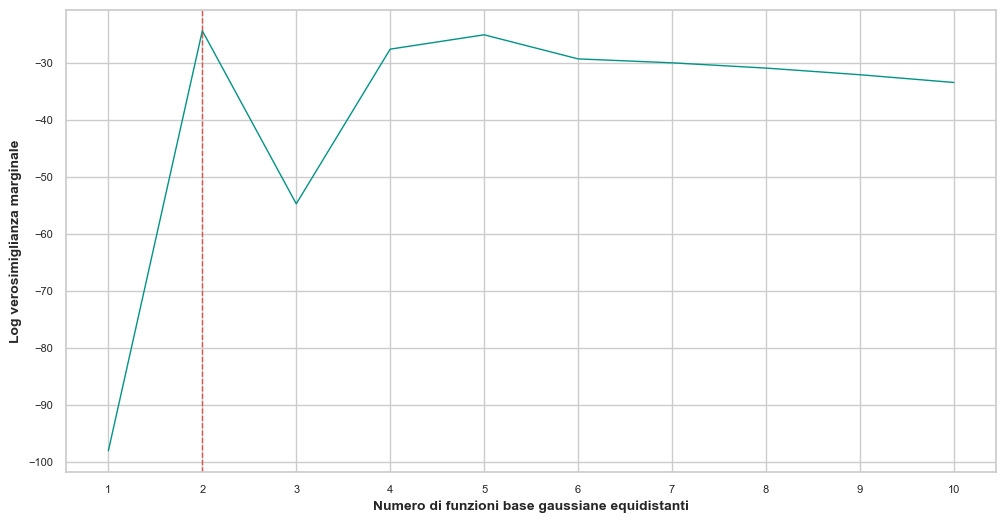

In [36]:
mlls = []

for d in range(1, m+1):
    mus = np.linspace(x0[0], x0[-1], d+1)
    args0 = {'bf': gaussian_basis_function, 'bf_args_list':[{'mu':mus[k]+.5*(mus[k+1]-mus[k])} for k in range(len(mus)-1)]}
    mll = log_marginal_likelihood(X0, t0, alpha, beta, args0)
    mlls.append(mll)

degree_max = np.argmax(mlls)+1
fig = plt.figure(figsize=(12,6))
sns.lineplot(x=np.ravel(range(1,m+1)), y=np.ravel(mlls), color=colors[6], linewidth=1)
plt.axvline(x=degree_max, linestyle='dashed', color=colors[2], lw=1)
plt.xticks(range(1, m+1))
plt.xlabel('Numero di funzioni base gaussiane equidistanti')
plt.ylabel('Log verosimiglianza marginale');

Nel caso considerato, annullando le derivate della log-evidenza rispetto ad $\alpha$ e $\beta$ si ottengono le condizioni
$$
\alpha = \frac{\gamma}{\mathbf{m}_p^T \mathbf{m}_p},\qquad
\frac{1}{\beta} = \frac{1}{n-\gamma} \sum_{i=1}^{n}(t_i - \mathbf{m}_p^T \boldsymbol\phi(\mathbf{x}_i))^2,
\qquad
\gamma = \sum_{i=0}^{m-1} \frac{\lambda_i}{\alpha+\lambda_i},
$$
dove $\lambda_i$ sono gli autovalori della matrice $\beta \boldsymbol\Phi^T \boldsymbol\Phi$. La quantità $\gamma$, compresa tra $0$ e $m$, è il **numero effettivo di parametri**: ogni termine è vicino a $1$ nelle direzioni in cui i dati determinano bene i parametri ($\lambda_i\gg\alpha$) e vicino a $0$ in quelle in cui domina il prior. La seconda condizione è la stima della varianza del rumore come media dei quadrati dei residui, con $n-\gamma$ al posto di $n$ per tener conto dei gradi di libertà usati dal modello.

Le soluzioni sono implicite, perché $\gamma$ e $\mathbf{m}_p$ dipendono da $\alpha$ e $\beta$: si parte da valori iniziali arbitrari e si iterano le due relazioni fino a convergenza.

`marginal_likelihood_maximization` implementa l'iterazione: a ogni passo calcola il posterior con i valori correnti, poi $\gamma$, poi i nuovi $\alpha$ e $\beta$, fermandosi quando entrambi cambiano meno della tolleranza relativa. Gli autovalori di $\boldsymbol\Phi^T\boldsymbol\Phi$ sono calcolati una sola volta e moltiplicati per $\beta$ a ogni iterazione.

In [37]:
def marginal_likelihood_maximization(X, t, args, alpha=1e-5, beta=1e-5, max_iter=200, rtol=1e-5, verbose=False):
    Phi = expand(X, **args)
    eigenvalues_0 = np.linalg.eigvalsh(Phi.T.dot(Phi))
    for i in range(max_iter):
        beta_prev = beta
        alpha_prev = alpha
        eigenvalues = eigenvalues_0*beta
        m_p, _ = mpe(X, t, alpha, beta, args)
        gamma = np.sum(eigenvalues/(eigenvalues + alpha))
        alpha = gamma/np.sum(m_p**2)
        beta_inv = 1/(Phi.shape[0]-gamma)*np.sum((t-Phi.dot(m_p))**2)
        beta =1/beta_inv
        if np.isclose(alpha_prev, alpha, rtol=rtol) and np.isclose(beta_prev, beta, rtol=rtol):
            if verbose:
                print(f'Convergenza dopo {i + 1} iterazioni.')
            return alpha, beta
    if verbose:
        print(f'Computazione fermata dopo {max_iter} iterazioni.')
    return alpha, beta

Applichiamo il metodo a $30$ punti equispaziati della sinusoide con rumore di deviazione standard $0.3$, con funzioni base polinomiali di grado da $0$ a $4$. Il valore stimato di $\beta$ va confrontato con quello vero, $1/0.3^2\approx11.1$: può risultare più piccolo, perché un polinomio di grado $4$ non approssima perfettamente la sinusoide, e lo scarto sistematico tra modello e funzione viene attribuito al rumore.

*Nota:* nella versione originale le potenze andavano da $1$ a $4$. Poiché `expand` non aggiunge la colonna di uni quando si usano funzioni base, il modello era privo del termine costante e non poteva rappresentare lo spostamento $0.5$ della sinusoide; per una frazione non trascurabile dei dataset generati casualmente (circa uno su sei) la massimizzazione dell'evidenza portava allora $\alpha\to\infty$, cioè a un modello con tutti i pesi nulli che attribuisce tutto al rumore. Includendo la potenza $0$, cioè la funzione base costante, il problema scompare.

Anche questa cella **ridefinisce** $\alpha$, $\beta$ e `args`, usati nelle celle successive.

In [38]:
N = 30

degree = 4

Xc = np.linspace(0, 1, N).reshape(-1, 1)
tc = g(Xc, noise_variance=0.3 ** 2)

args = {'bf': polynomial_basis_function, 'bf_args_list':[{'power':k} for k in range(0, degree + 1)]}

alpha, beta, = marginal_likelihood_maximization(Xc, tc, args, rtol=1e-5, verbose=True)
print('alpha* = {}'.format(alpha))
print('beta* = {}'.format(beta))

Convergenza dopo 22 iterazioni.
alpha* = 0.9409307608271162
beta* = 2.9450611909108435


In alternativa si può usare la classe `BayesianRidge` di `scikit-learn`, i cui metodi `fit` e `predict` corrispondono alle funzioni `mpe` e `posterior_predictive` definite sopra, con stima degli iperparametri inclusa. L'implementazione è molto simile a quella vista, con una differenza: usa distribuzioni **Gamma** come prior per gli iperparametri, che favoriscono valori piccoli. Nell'implementazione precedente lo stesso effetto si ottiene, in modo più semplice, partendo da valori iniziali piccoli di $\alpha$ e $\beta$.

**Attenzione ai nomi:** in `BayesianRidge` l'attributo `alpha_` è la precisione del **rumore** (il nostro $\beta$), mentre `lambda_` è la precisione del **prior** sui pesi (il nostro $\alpha$).

In [39]:
from sklearn.linear_model import BayesianRidge
Phi = expand(Xc, **args)
br = BayesianRidge(fit_intercept=False, tol=1e-5, verbose=True)
br.fit(Phi, tc.ravel())
print('alpha* = {}'.format(br.lambda_))
print('beta* = {}'.format(br.alpha_))

Convergence after  23  iterations
alpha* = 0.9409195918776262
beta* = 2.945064003065024


I valori di $\alpha$ e $\beta$ ottenuti con le due implementazioni sono praticamente identici. Confrontiamo ora anche le predizioni e le loro incertezze su un insieme di punti di test: i risultati con prefisso `np` sono quelli della nostra implementazione, quelli con prefisso `br` quelli di `BayesianRidge`.

*Nota:* nella versione originale questa parte usava il posterior e le funzioni base dell'esempio precedente, con le gaussiane, e non calcolava le predizioni di `BayesianRidge`; le due celle seguenti sono state riscritte per eseguire effettivamente il confronto sullo stesso modello.

In [40]:
# punti di test nell'intervallo [0,1]
X_test = np.random.rand(10).reshape(-1,1)
# posterior con gli iperparametri stimati e le funzioni base polinomiali
m_p, Sigma_p = mpe(Xc, tc, alpha, beta, args)

In [41]:
y_np_mean, y_np_var = posterior_predictive(X_test, m_p, Sigma_p, beta, args)
y_br_mean, y_br_std = br.predict(expand(X_test, **args), return_std=True)

print('np, media predittiva: {}'.format(np.round(y_np_mean.ravel(), 4)))
print('br, media predittiva: {}'.format(np.round(y_br_mean, 4)))
print('np, std predittiva:   {}'.format(np.round(np.sqrt(y_np_var.ravel()), 4)))
print('br, std predittiva:   {}'.format(np.round(y_br_std, 4)))

np, media predittiva: [ 1.008  -0.0154 -0.3928  0.5331 -0.0227  0.9703  0.6892  0.9989  0.3345
  0.8134]
br, media predittiva: [ 1.008  -0.0154 -0.3928  0.5331 -0.0227  0.9703  0.6892  0.9989  0.3345
  0.8134]
np, std predittiva:   [0.6155 0.6015 0.6351 0.5986 0.6016 0.6079 0.5975 0.6132 0.5998 0.5981]
br, std predittiva:   [0.6155 0.6015 0.6351 0.5986 0.6016 0.6079 0.5975 0.6132 0.5998 0.5981]


## Il kernel equivalente

La media della distribuzione predittiva,
$$
\boldsymbol\phi(\mathbf{x})^T\mathbf{m}_p=\beta\,\boldsymbol\phi(\mathbf{x})^T\boldsymbol\Sigma_p\boldsymbol\Phi^{T}\mathbf{t},
$$
può essere scritta, poiché $\boldsymbol\Phi^T\mathbf{t}=\sum_i\boldsymbol\phi(\mathbf{x}_i)t_i$, come
$$
\boldsymbol\phi(\mathbf{x})^T\mathbf{m}_p=\sum_{i=1}^{n}\beta\,\boldsymbol\phi(\mathbf{x})^T\boldsymbol\Sigma_p\boldsymbol\phi(\mathbf{x}_{i})\,t_{i}.
$$
La predizione è quindi una **combinazione lineare dei target** $t_i$ del training set, con pesi che dipendono dagli elementi $\mathbf{x}_i$ e dal punto $\mathbf{x}$ in cui si predice; nessun vettore di parametri compare esplicitamente. La funzione dei pesi,
$$
\kappa(\mathbf{x},\mathbf{x}')=\beta\,\boldsymbol\phi(\mathbf{x})^T\boldsymbol\Sigma_p\boldsymbol\phi(\mathbf{x}'),
$$
è detta **kernel equivalente** (si vedano le note).

`equiv_kernel` calcola il kernel equivalente tra due punti (convertito in scalare, perché viene usato con `np.vectorize`, che nelle versioni recenti di `numpy` non accetta valori di ritorno di tipo array); `predict_equiv_kernel` calcola le predizioni come combinazione pesata dei target. Le due celle successive verificano che le predizioni così ottenute nei punti di test (le croci) coincidono con quelle del modello, per la retta e per la sinusoide.

In [42]:
def equiv_kernel(x1, x2, X, t, alpha, beta, args):
    phi_1 = expand(x1, **args)
    phi_2 = expand(x2, **args)
    _, Sigma_p = mpe(X, t, alpha, beta, args)
    return (beta*phi_1@Sigma_p@(phi_2.T)).item()

In [43]:
def predict_equiv_kernel(X_test, X, t, alpha, beta, args):
    phi_1 = expand(X_test, **args)
    phi_2 = expand(X, **args)
    _, Sigma_p = mpe(X, t, alpha, beta, args)
    return beta*phi_1@Sigma_p@(phi_2.T)@t

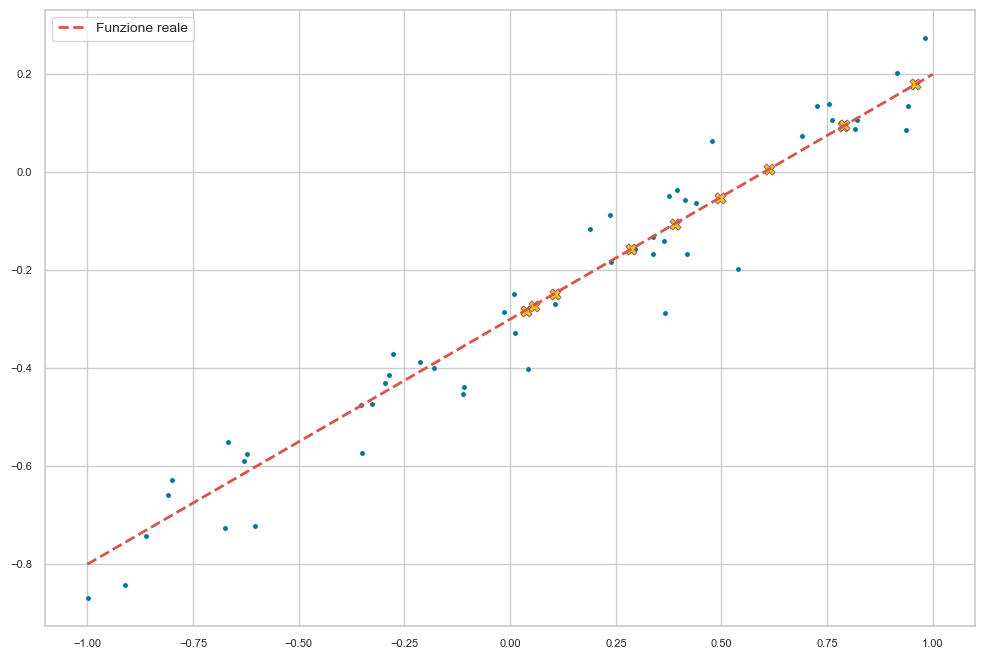

In [44]:
args = {}
plt.figure(figsize=(12,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=15, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Funzione reale')
sns.scatterplot(x=np.ravel(X_test), y=np.ravel(predict_equiv_kernel(X_test, X, t1, alpha, beta, args)), color=colors[7], edgecolor=colors[5], marker='X')
plt.show()

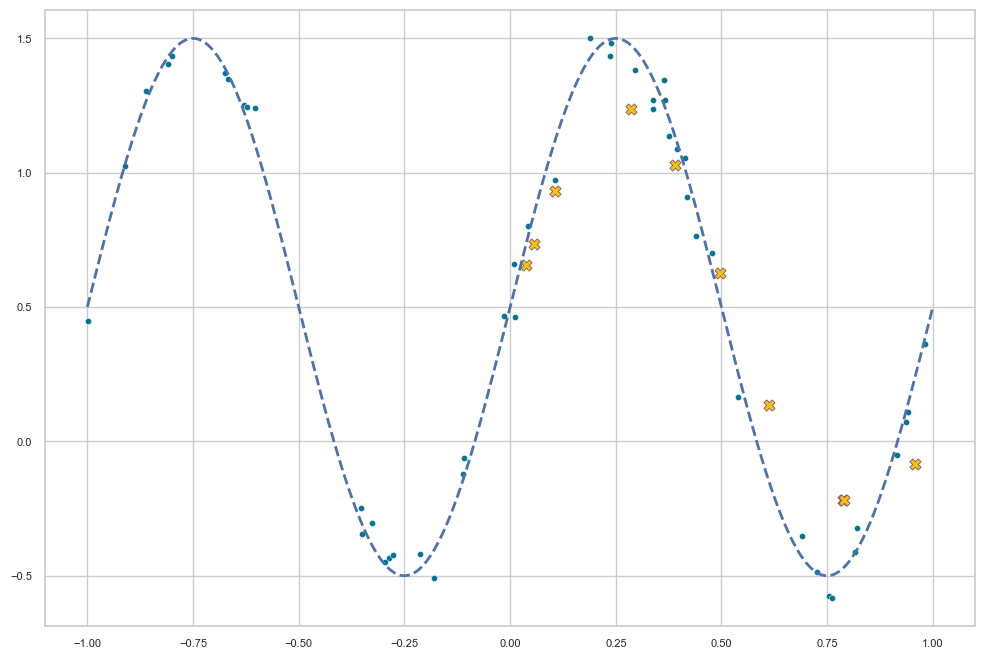

In [45]:
args = {}
plt.figure(figsize=(12,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=2, linestyle='dashed')
sns.scatterplot(x=np.ravel(X_test), y=np.ravel(predict_equiv_kernel(X_test, X, t2, alpha, beta, args2)), color=colors[7], edgecolor=colors[5], marker='X')
plt.show()

Le immagini seguenti riportano il valore del kernel equivalente, con colori più caldi per valori più alti, per tutte le coppie di punti in $[-1,1]\times[-1,1]$, per due diversi insiemi di funzioni base. Il kernel è più grande per coppie di valori vicini, cioè lungo la diagonale: nella predizione in $\mathbf{x}$, i target degli elementi del training set vicini a $\mathbf{x}$ ricevono un peso maggiore. È un principio di **località**, che non è stato imposto ma emerge dalla media bayesiana sui parametri: gli esempi vicini sono più rilevanti per la predizione.

Il primo grafico usa la funzione base identità, cioè il modello lineare $w_0+w_1x$: in questo caso il kernel equivalente non è localizzato (dipende linearmente da $x$ e $x'$), perché una retta è determinata globalmente da tutti i punti. Il secondo usa le funzioni base sigmoidali, e mostra la struttura localizzata attorno alla diagonale.

In [46]:
n_values = 200
xx = np.linspace(-1, 1, n_values)
yy = np.linspace(-1, 1, n_values)
XX,YY = np.meshgrid(xx, yy)
func=np.vectorize(lambda x,y:equiv_kernel(x,y,X,t1,alpha,beta,args1))
Z=func(XX,YY)

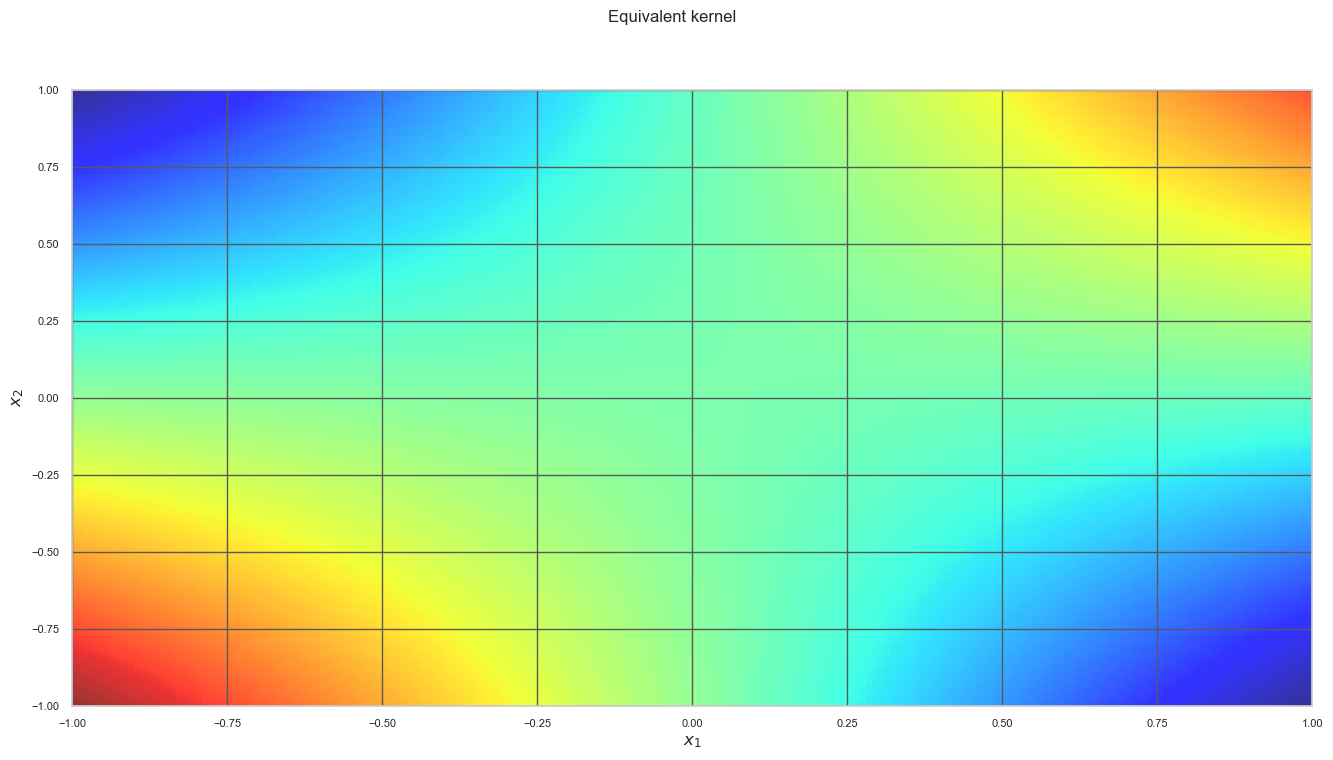

In [47]:
fig = plt.figure(figsize=(16,8))
ax=fig.gca()
imshow_handle = ax.imshow(Z, origin='lower', extent=(xx.min(),xx.max(), yy.min(), yy.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$x_1$', fontsize=12)
ax.set_ylabel('$x_2$', fontsize=12)
plt.xlim(-1,1)
plt.ylim(-1,1)
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(which='both', color='0.35')
plt.suptitle(u'Equivalent kernel')
plt.show()

In [48]:
n_values = 200
xx = np.linspace(-1, 1, n_values)
yy = np.linspace(-1, 1, n_values)
XX,YY = np.meshgrid(xx, yy)
func = np.vectorize(lambda x,y:equiv_kernel(x,y,X,t2,alpha,beta,args2))
Z = func(XX,YY)

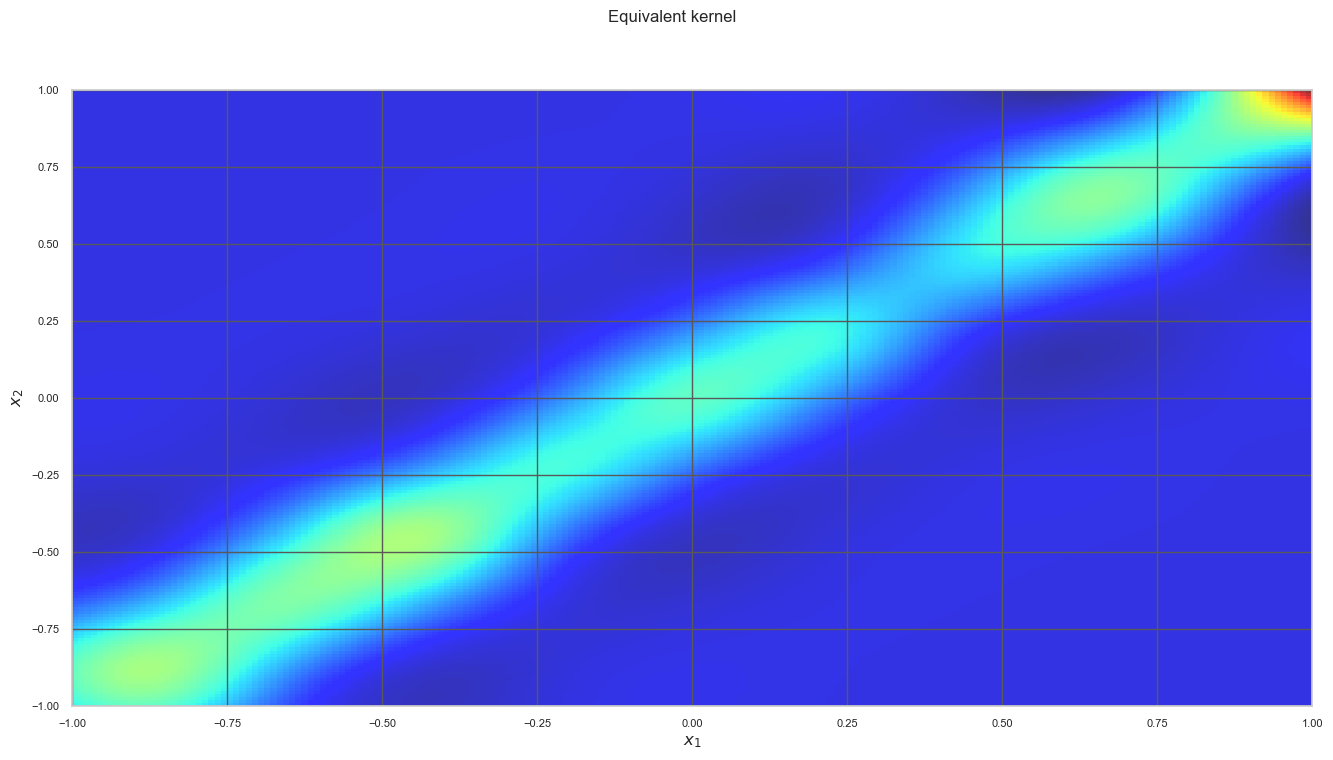

In [49]:
fig = plt.figure(figsize=(16,8))
ax=fig.gca()
imshow_handle = ax.imshow(Z, origin='lower', extent=(xx.min(),xx.max(), yy.min(), yy.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$x_1$', fontsize=12)
ax.set_ylabel('$x_2$', fontsize=12)
plt.xlim(-1,1)
plt.ylim(-1,1)
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(which='both', color='0.35')
plt.suptitle(u'Equivalent kernel')
plt.show()

Il kernel equivalente è un esempio di modello **non parametrico**: la predizione non è ottenuta applicando una funzione parametrica all'elemento, ma come combinazione lineare pesata dei target in $\mathbf{t}$, in cui il peso di $t_i$ è definito da una **misura di similarità** tra l'elemento corrispondente $\mathbf{x}_i$ e l'elemento $\mathbf{x}$ di cui si vuole predire il target. La similarità è espressa da una funzione **kernel** $\kappa(\mathbf{x}_i,\mathbf{x})$.

### Kernel regression

Nei metodi di kernel regression il target di un elemento $\mathbf{x}$ è predetto facendo riferimento agli elementi del training set, e in particolare a quelli più vicini a $\mathbf{x}$, attraverso una funzione **kernel** $\kappa_h(\mathbf{x})$, non trascurabile solo in un intorno di $\mathbf{0}$. Il parametro $h$ è l'ampiezza di banda (*bandwidth*), che controlla la larghezza dell'intorno (nelle note è indicata con $s$, per non confonderla con il predittore $h$). Un kernel comune è quello gaussiano (RBF),
$$
\kappa_h(\mathbf{x})=e^{-\frac{{\left\lVert\mathbf{x}\right\rVert}^2}{2h^2}}.
$$

In regressione, con loss quadratica, si vuole stimare la media condizionata
$$
f(\mathbf{x})= \mathbb{E}[{t\mid\mathbf{x}}]=\int t\,p(t\mid\mathbf{x})\,dt=\frac{\int t\;p(\mathbf{x},t)\,dt}{\int p(\mathbf{x},t)\,dt}.
$$
Approssimando la distribuzione congiunta, sconosciuta, con una **stima kernel della densità**, che pone una "campana" su ciascuna coppia del training set,
$$
 p(\mathbf{x},t)\approx\frac{1}{n}\sum_{i=1}^n\kappa_h(\mathbf{x}-\mathbf{x}_i)\,\kappa_h(t-t_i),
$$
e usando il fatto che $\kappa_h$ è una densità con media nulla, si ottiene lo **stimatore di Nadaraya–Watson**
$$
 f(\mathbf{x})=\frac{\sum_{i=1}^n\kappa_h(\mathbf{x}-\mathbf{x}_i)\,t_i}{\sum_{i=1}^n\kappa_h(\mathbf{x}-\mathbf{x}_i)}=\sum_{i=1}^nw_i(\mathbf{x})\,t_i,
 \qquad
 w_i(\mathbf{x})=\frac{\kappa_h(\mathbf{x}-\mathbf{x}_i)}{\sum_{j=1}^n\kappa_h(\mathbf{x}-\mathbf{x}_j)}:
$$
la predizione è una combinazione convessa di tutti i target, pesati dal kernel. Gli elementi vicini a $\mathbf{x}$ dominano, quelli lontani hanno peso trascurabile.

`kernel` calcola la matrice dei valori del kernel gaussiano tra gli elementi del training set (righe) e i punti di predizione (colonne); `predict_kernel` calcola le predizioni di Nadaraya–Watson. Se vengono specificate funzioni base, le distanze sono calcolate nello spazio trasformato $\boldsymbol\phi(\mathbf{x})$.

In [50]:
def kernel(x, X, sigma):
    dist_mat = cdist(X, x, 'minkowski', p=2.)
    return np.exp((-0.5 / (sigma ** 2)) * (dist_mat ** 2))

In [51]:
def predict_kernel(x, X, t, h, args):
    weights = kernel(expand(x, **args), expand(X, **args), h)
    y = (weights*t).sum(axis=0)/weights.sum(axis=0)
    if np.isscalar(x):
        return y.item()
    else:
        return y

Con una bandwidth piccola, $h=0.05$, la predizione segue da vicino i singoli punti, e risulta irregolare: ogni predizione è la media di pochissimi target, e ne riproduce il rumore. Si noti anche la distorsione ai bordi dell'intervallo, dove l'intorno è "tagliato" da un lato e la media tende verso l'interno.

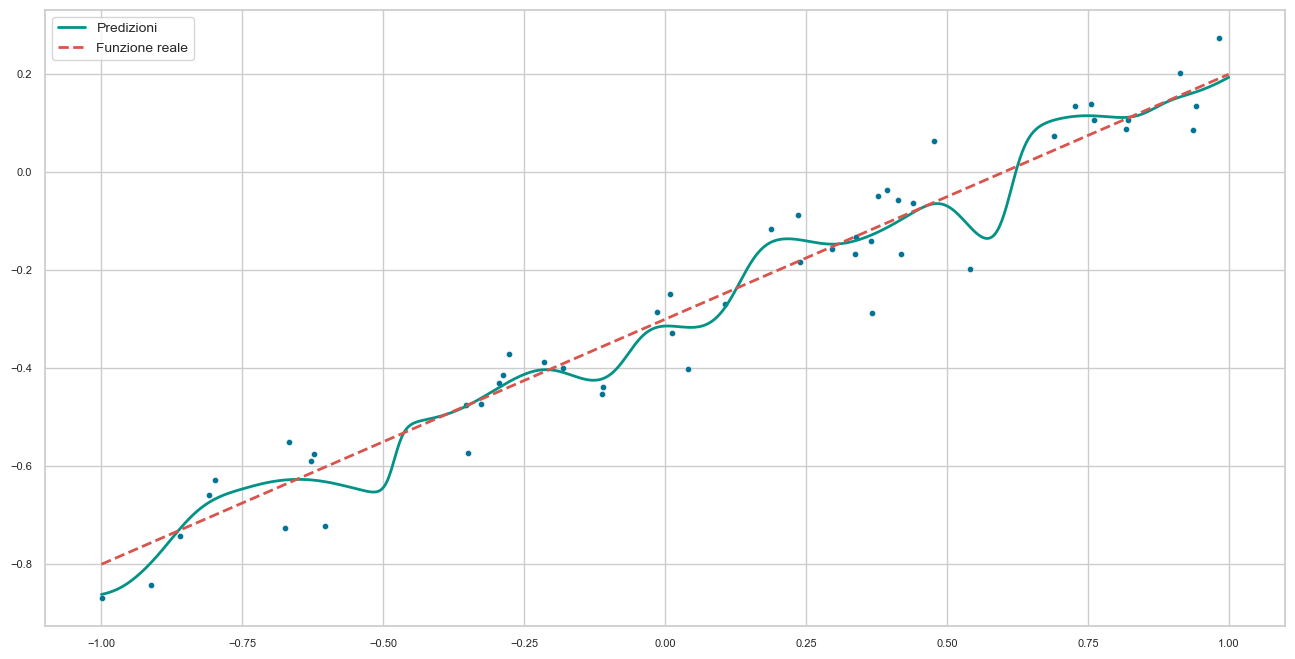

In [52]:
args = {}
h = .05
fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict_kernel(x,X, t1, h, args)), linewidth=2, color=colors[6], label='Predizioni')
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Funzione reale')
plt.legend()
plt.show()

Per la sinusoide, con le distanze calcolate nello spazio delle funzioni base sigmoidali.

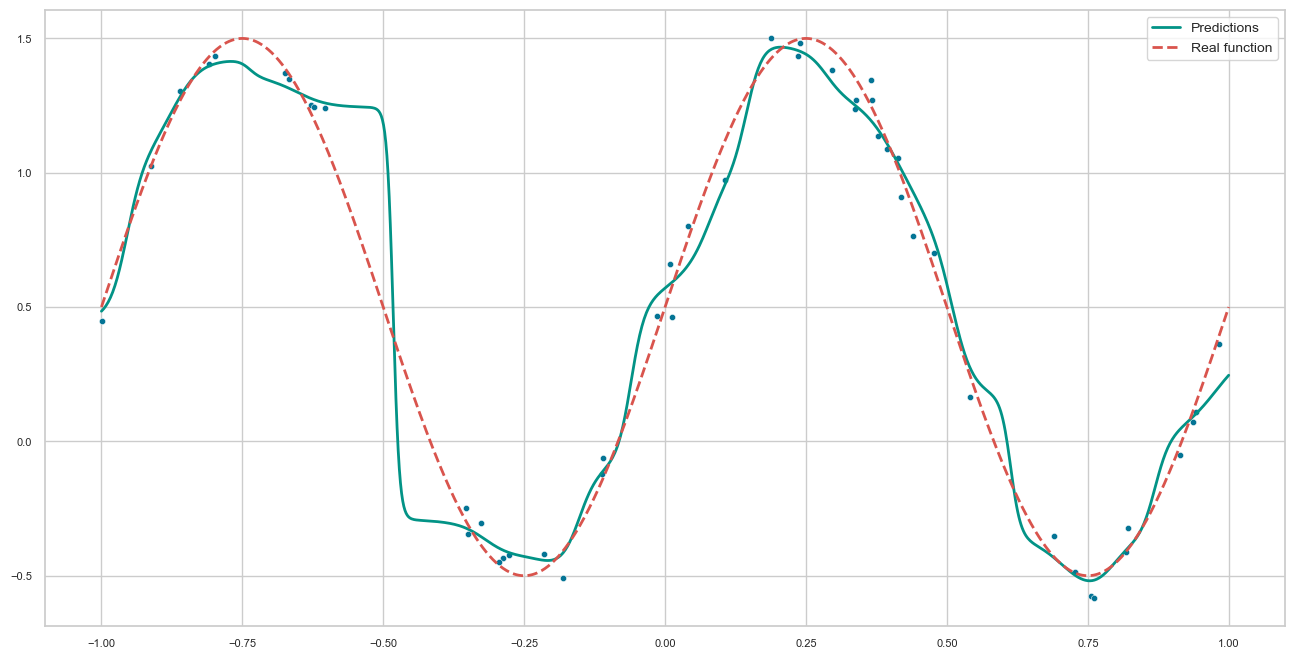

In [53]:
k = 10
mus = np.linspace(-1, 1, k)
args = {'bf': sigmoid_basis_function, 'bf_args_list':[{'mu':mu} for mu in mus]}
h = .1

fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict_kernel(x, X, t2, h, args)), linewidth=2, color=colors[6], label='Predictions')
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.legend()
plt.show()

La bandwidth migliore può essere scelta, all'interno di un insieme di valori, come quella che dà le predizioni migliori. Per non usare un insieme di validazione separato, `select_bandwidth` usa la **leave-one-out cross-validation**: ogni elemento del training set è predetto con lo stimatore costruito su tutti gli altri, il che, per Nadaraya–Watson, equivale semplicemente ad azzerare la diagonale della matrice dei pesi. Senza escludere l'elemento stesso, il criterio favorirebbe bandwidth sempre più piccole, fino a riprodurre esattamente i target del training set.

In [54]:
def select_bandwidth(X, t, hs, args):
    mse = []
    for h in hs:
        XX = expand(X, **args)
        weights = kernel(XX, XX, h)
        weights = weights - np.diag(np.diag(weights))
        y = (weights*t).sum(axis=0)/weights.sum(axis=0)
        mse.append(((y[:, np.newaxis] - t) ** 2).mean())
    return hs[np.argmin(mse)]

Con la bandwidth scelta per cross-validation la predizione è molto più regolare. Per la retta il valore scelto è tra i più grandi dell'insieme: un intorno ampio fa la media di molti punti e riduce il rumore, e la distorsione introdotta è piccola dove la funzione è quasi lineare; restano però gli effetti di bordo.

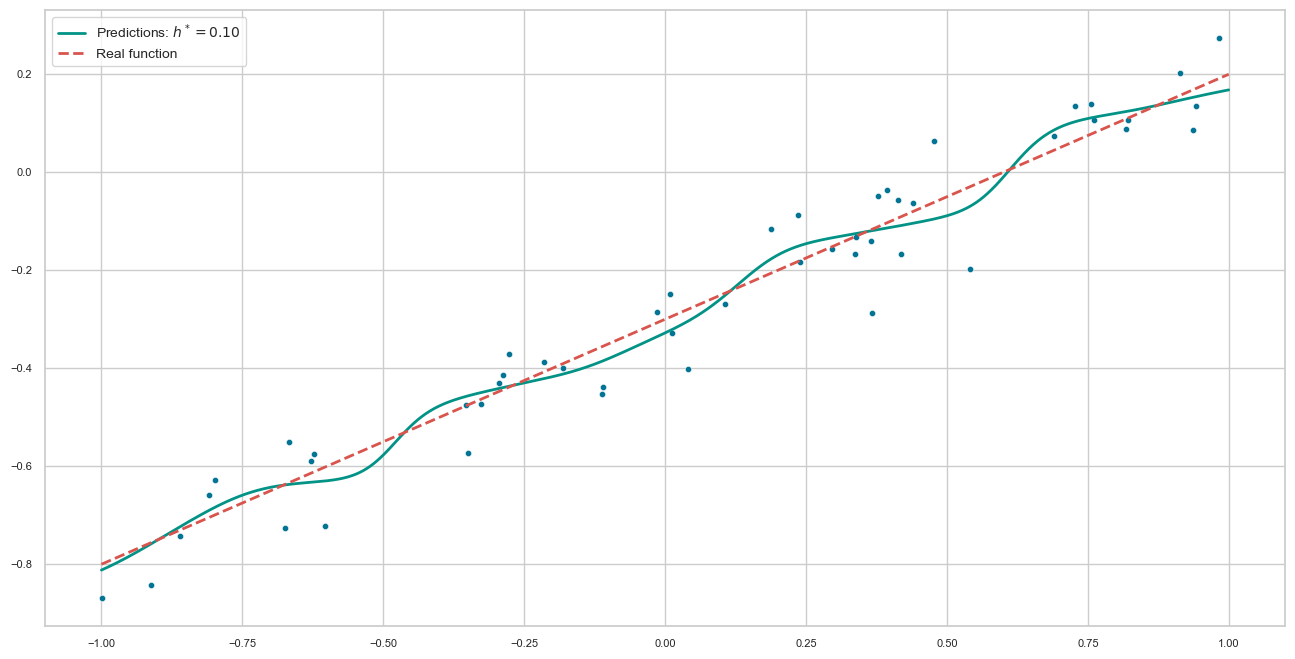

In [55]:
args = {}
hs=np.linspace(0.1, 1, 10)
h_star = select_bandwidth(X, t1, hs, args)
fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict_kernel(x,X, t1, h_star, args)), linewidth=2, color=colors[6], label=f'Predictions: $h^*={h_star:3.2f}$')
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.legend()
plt.show()

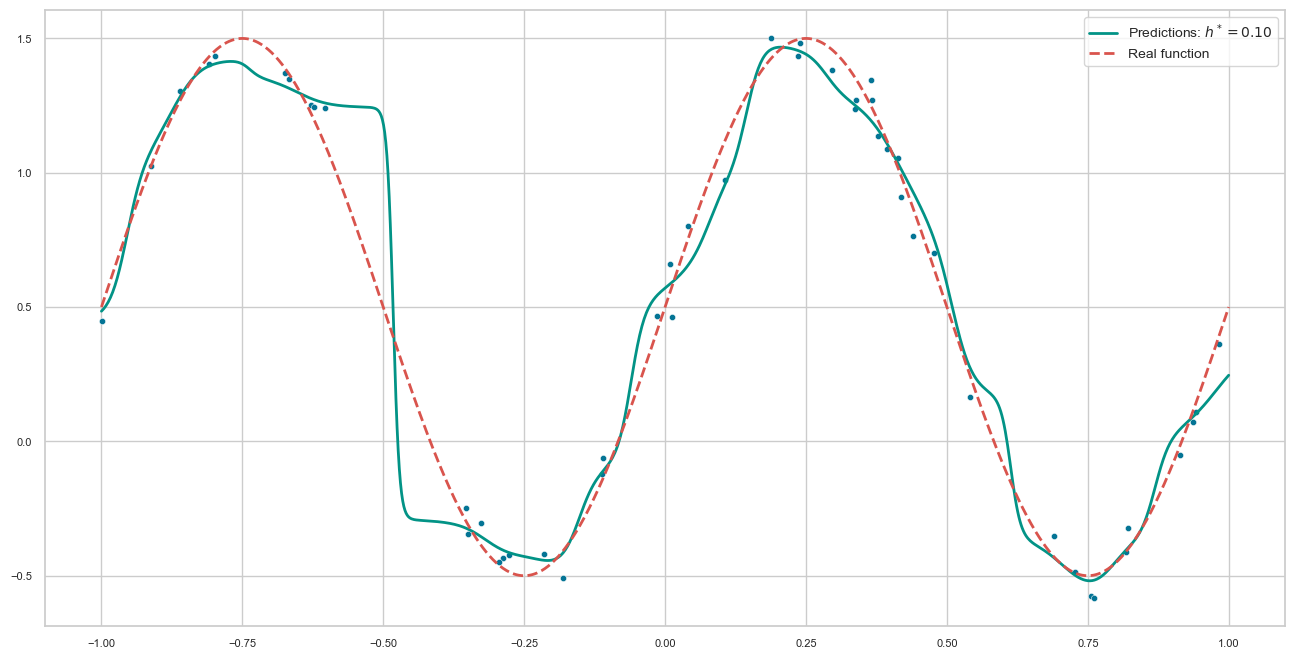

In [56]:
k = 10
mus = np.linspace(-1, 1, k)
args = {'bf': sigmoid_basis_function, 'bf_args_list':[{'mu':mu} for mu in mus]}

hs = np.linspace(0.1, 1, 10)
h_star = select_bandwidth(X, t2, hs, args)

fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(predict_kernel(x, X, t2, h_star, args)), linewidth=2, color=colors[6], label=f'Predictions: $h^*={h_star:3.2f}$')
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.legend()
plt.show()

## Regressione localmente pesata

Lo stimatore di Nadaraya–Watson adatta, in ogni intorno, una **costante**: funziona bene dove la funzione è quasi piatta alla scala della bandwidth, ma introduce una distorsione sistematica dove ha una pendenza, soprattutto ai bordi dei dati. La **regressione localmente pesata** (LOESS) adatta invece, per ogni punto $\mathbf{x}$ in cui predire, un **modello lineare**, minimizzando una versione pesata della somma dei quadrati dei residui,
$$
L(\mathbf{x})=\sum_{i=1}^n\kappa_i(\mathbf{x})(\mathbf{w}^T\overline{\mathbf{x}}_i-t_i)^2,
\qquad
\kappa_i(\mathbf{x})=\kappa_h(\mathbf{x}-\mathbf{x}_i),
$$
in cui il peso di ogni elemento dipende dalla sua distanza da $\mathbf{x}$.

`kernel_loess` calcola il kernel gaussiano tra un punto e tutti gli elementi del training set.

*Nota:* nella versione originale questa funzione si chiamava `kernel`, come quella definita per la kernel regression, che veniva così sovrascritta con una funzione dalla firma diversa: la selezione della bandwidth nelle celle finali usava quindi la funzione sbagliata e produceva valori non validi. La funzione è stata rinominata.

In [57]:
def kernel_loess(x,xi,h):
    return np.exp(np.sum((xi - x) ** 2, axis=1) / (-2 * h * h))

La minimizzazione di questa loss,
$$
\hat{\mathbf{w}}(\mathbf{x})=\underset{\mathbf{w}}{\mathrm{argmin}}\sum_{i=1}^n\kappa_h(\mathbf{x}-\mathbf{x}_i)(\mathbf{w}^T\overline{\mathbf{x}}_i-t_i)^2,
$$
è un problema di minimi quadrati pesati, la cui soluzione generalizza le equazioni normali:
$$
\hat{\mathbf{w}}(\mathbf{x}) = (\overline{\mathbf{X}}^T\boldsymbol\Psi(\mathbf{x})\overline{\mathbf{X}})^{-1}\overline{\mathbf{X}}^T\boldsymbol\Psi(\mathbf{x})\mathbf{t},
$$
dove $\boldsymbol\Psi(\mathbf{x})$ è la matrice diagonale $n\times n$ con elementi $\boldsymbol\Psi(\mathbf{x})_{ii}=\kappa_h(\mathbf{x}-\mathbf{x}_i)$. I parametri cambiano con il punto $\mathbf{x}$: ogni predizione richiede la soluzione di un sistema lineare.

In [58]:
def diag_kernel(x, X, h):
    return np.diag(kernel_loess(X,x,h))

`local_regression_coeffs` calcola i coefficienti locali; la pseudo-inversa (`pinv`) evita problemi quando, con bandwidth molto piccola, quasi tutti i pesi sono nulli e la matrice è (quasi) singolare.

In [59]:
def local_regression_coeffs(x, X, t, h):
    psi = diag_kernel(x, X, h)
    X_ext = np.c_[np.ones(len(X)), X]
    return np.linalg.pinv((X_ext.T @ psi) @ X_ext) @ X_ext.T @ psi @ t

La predizione in $\mathbf{x}$ si ottiene poi applicando il modello lineare locale, $y = \overline{\mathbf{x}}^T\hat{\mathbf{w}}(\mathbf{x})$.

In [60]:
def local_regression(x, X, t, h):
    x_ext = np.r_[1, x]
    w = local_regression_coeffs(x, X, t, h)
    return x_ext @ w

Un esempio in un singolo punto, $x=0.1$, con $h=0.05$: il grafico mostra i pesi $\kappa_h(x-x_i)$ in funzione di $x_i$, che sono non trascurabili solo in un intorno di ampiezza circa $3h$ attorno a $x$.

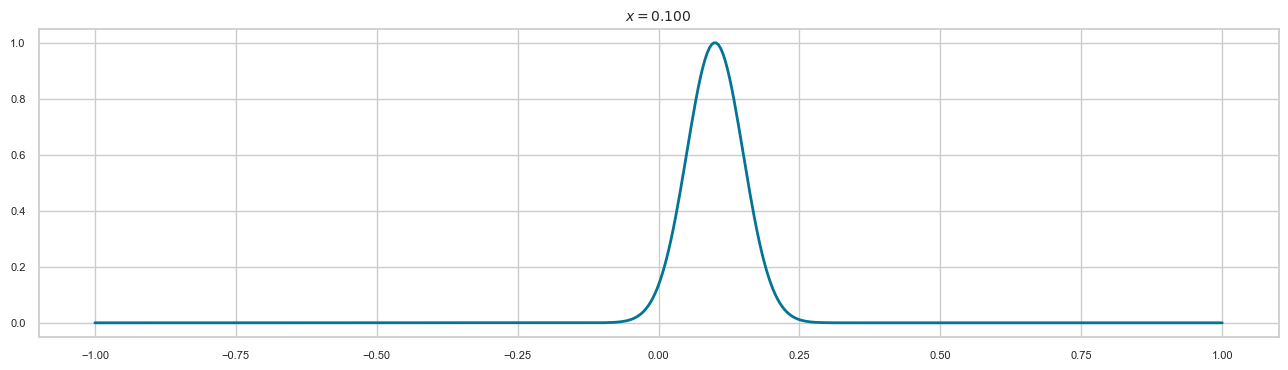

In [61]:
h = .05

x_ = 0.1

# calcola matrice kernel
psi = diag_kernel(np.array([x_]).reshape(-1,1),X,h)
domain = np.linspace(-1, 1, num=500)
f = plt.figure(figsize=(16,4))
plt.title('$x={0:5.3f}$'.format(x_))
sns.lineplot(x=np.ravel(domain), y=np.ravel(kernel_loess(x_,domain.reshape(-1,1),h)), color=colors[1])
plt.show()

In [62]:
y = local_regression(x_, X, t1, h)
w = local_regression_coeffs(x_, X, t1, h)

La retta locale stimata in $x=0.1$ (in tutto il dominio, anche se è significativa solo vicino a $x$) e la predizione corrispondente (il punto).

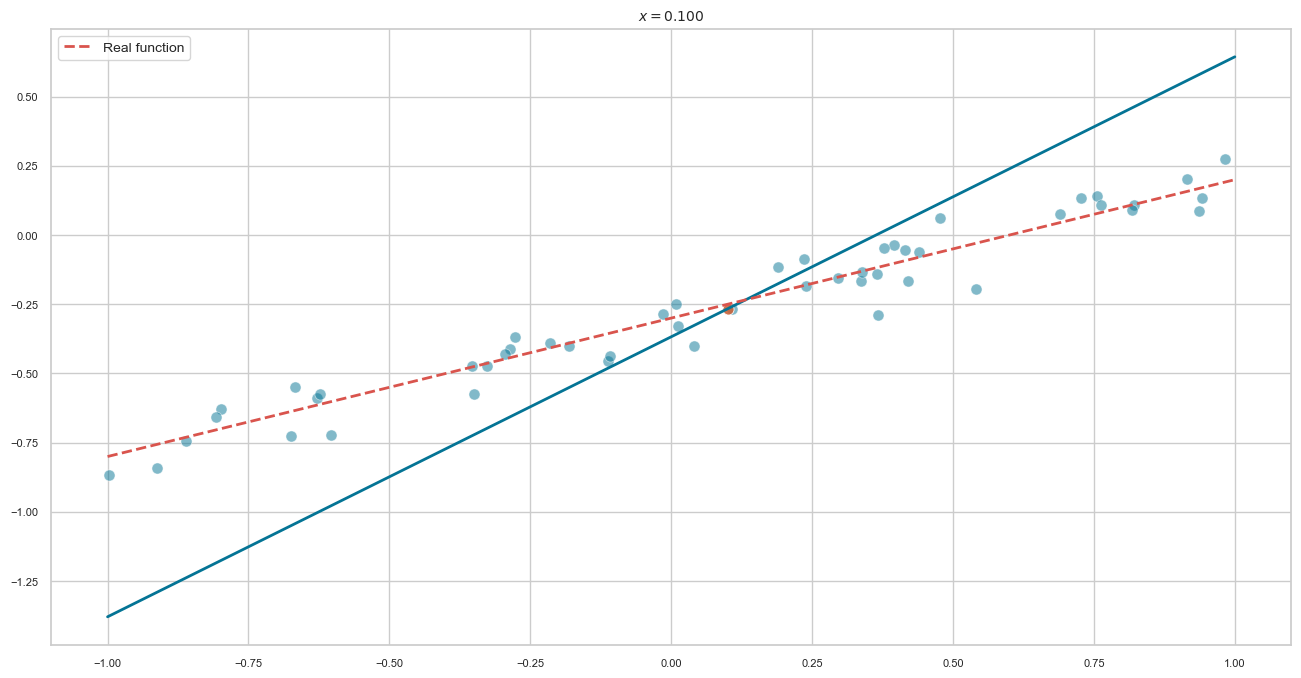

In [63]:
f = plt.figure(figsize=(16,8))
plt.title('$x={0:5.3f}$'.format(x_))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), color=colors[1], alpha=.5)
sns.scatterplot(x=np.ravel([x_]), y=np.ravel([y]), marker='o', color=colors[4], alpha=.9)
sns.lineplot(x=np.ravel(domain), y=np.ravel(np.c_[np.ones(len(domain)), domain] @ w), color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.show()

Ripetendo il calcolo per tutti i punti della griglia si ottiene la funzione predittiva della LOESS.

In [64]:
prediction = [local_regression(x, X, t1, h) for x in domain]

Con $h=0.05$ ogni retta locale è stimata su pochi punti, e la predizione è irregolare. Rispetto a Nadaraya–Watson con la stessa bandwidth, però, non c'è la distorsione ai bordi: una retta locale segue la pendenza della funzione anche dove l'intorno è unilaterale.

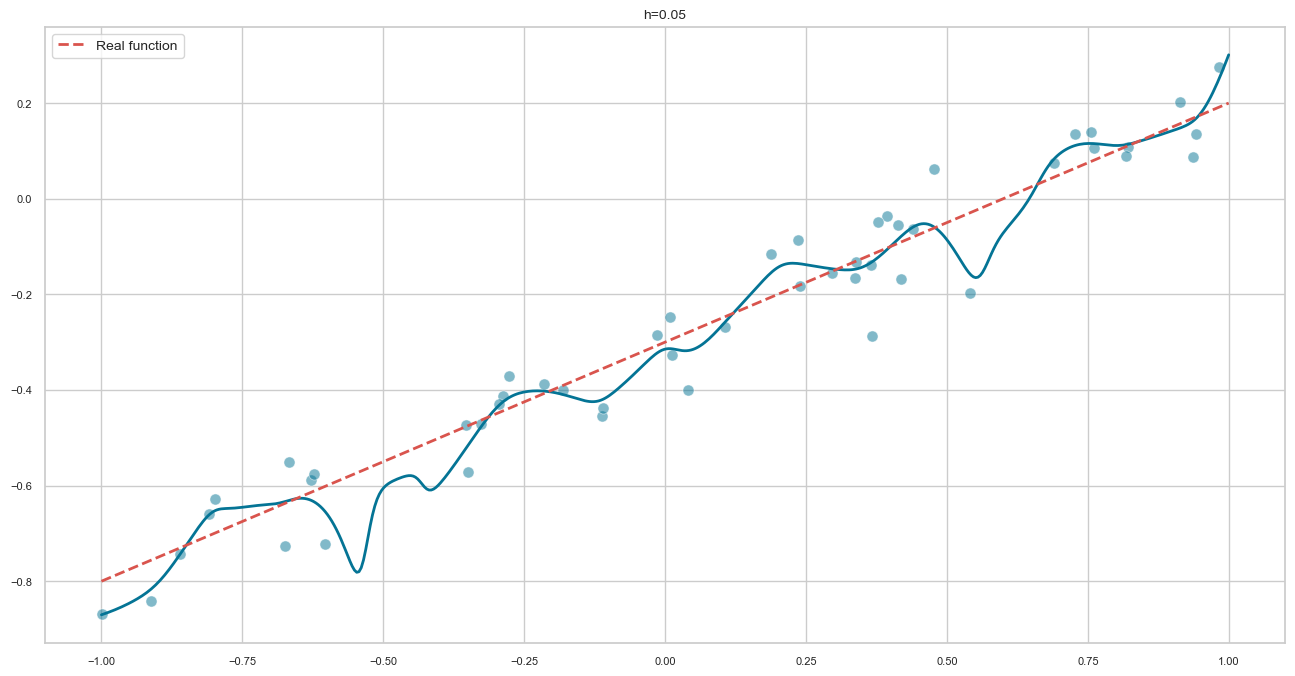

In [65]:
f = plt.figure(figsize=(16,8))
plt.title('h=%g' % h)
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), color=colors[1], alpha=.5)
sns.lineplot(x=np.ravel(domain), y=np.ravel(prediction), linewidth=2, color=colors[1])
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.show()

### Scelta della bandwidth per la LOESS

Come per la kernel regression, la bandwidth può essere scelta per **leave-one-out cross-validation**: ogni elemento è predetto con il modello locale stimato su tutti gli altri elementi, e si sceglie la bandwidth con il minimo errore quadratico medio.

*Nota:* la versione originale di questa funzione prediceva ogni elemento usando anche l'elemento stesso (favorendo bandwidth piccolissime), applicava la LOESS a una matrice che conteneva già la colonna di uni, e il risultato non veniva usato; la cella finale usava invece la selezione della kernel regression. Le celle seguenti sono state riscritte.

In [66]:
def select_bandwidth_loess(X, t, hs):
    # leave-one-out: ogni elemento e' predetto con il modello locale stimato sugli altri
    mse = []
    for h in hs:
        errs = []
        for i in range(len(X)):
            mask = np.arange(len(X)) != i
            y = local_regression(X[i], X[mask], t[mask], h)
            errs.append((y.item() - t[i].item()) ** 2)
        mse.append(np.mean(errs))
    return hs[np.argmin(mse)], np.min(mse)

In [67]:
hs = np.linspace(0.05, 1, 20)
h_star, mse = select_bandwidth_loess(X, t1, hs)

Per la retta, la cross-validation sceglie una bandwidth relativamente ampia (il valore esatto varia da un campione all'altro): poiché i dati sono generati da una retta, il modello lineare locale è corretto ovunque, e conviene usare il maggior numero possibile di punti per ridurre il rumore. Al limite, con $h\to\infty$, la LOESS coincide con la regressione lineare ordinaria.

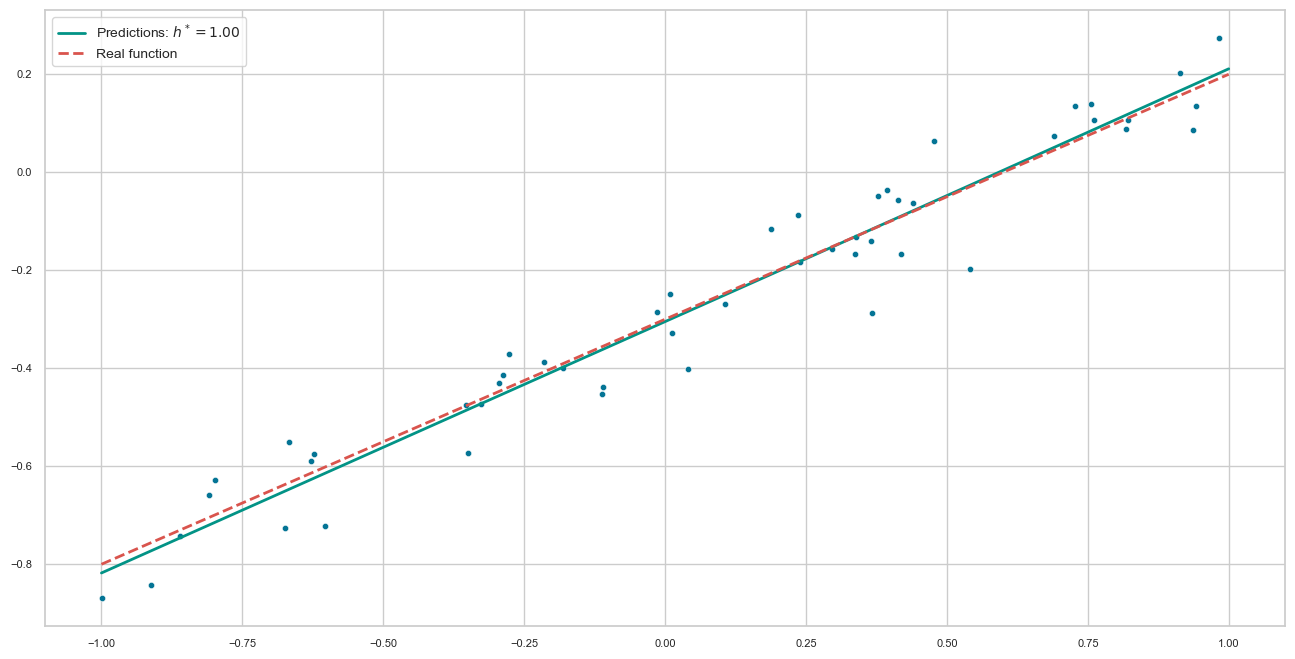

In [68]:
prediction_star = [local_regression(x, X, t1, h_star) for x in domain]
fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t1), s=20, color=colors[1])
sns.lineplot(x=np.ravel(domain), y=np.ravel(prediction_star), linewidth=2, color=colors[6], label=f'Predictions: $h^*={h_star:3.2f}$')
sns.lineplot(x=np.ravel(x), y=np.ravel(y1), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.legend()
plt.show()

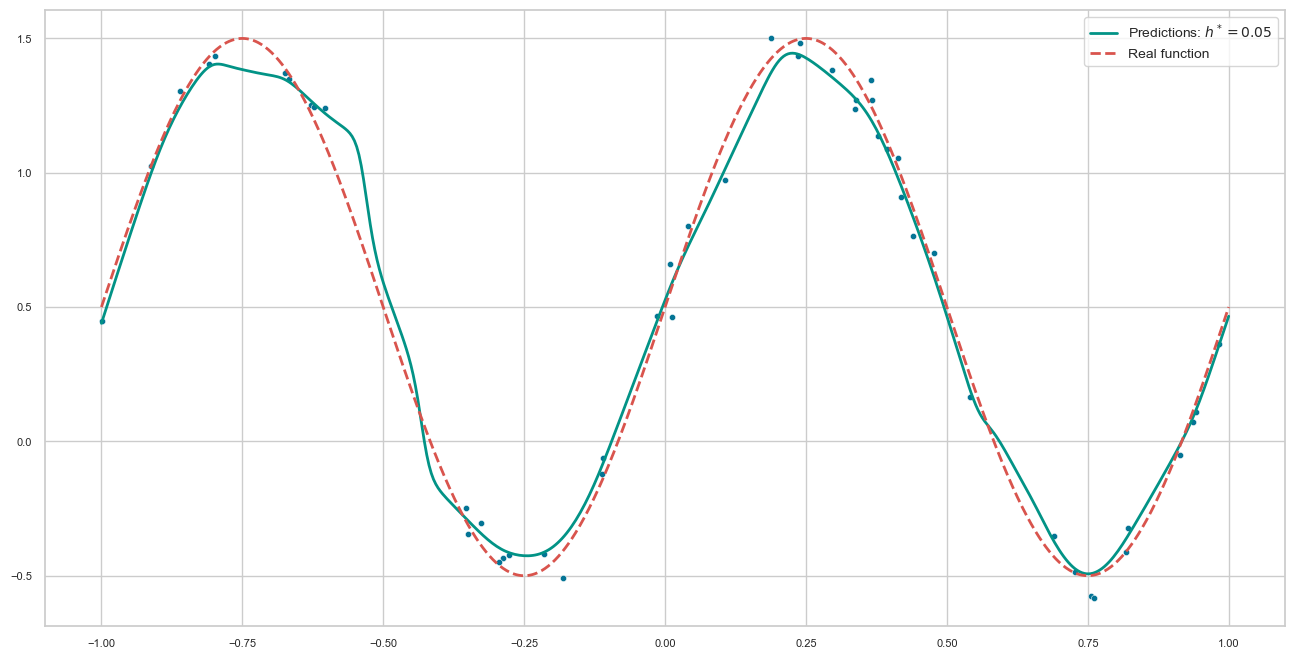

In [69]:
h_star2, mse2 = select_bandwidth_loess(X, t2, hs)
prediction_star2 = [local_regression(x, X, t2, h_star2) for x in domain]
fig = plt.figure(figsize=(16,8))
sns.scatterplot(x=np.ravel(X), y=np.ravel(t2), s=20, color=colors[1])
sns.lineplot(x=np.ravel(domain), y=np.ravel(prediction_star2), linewidth=2, color=colors[6], label=f'Predictions: $h^*={h_star2:3.2f}$')
sns.lineplot(x=np.ravel(x), y=np.ravel(y2), linewidth=2, color=colors[2], linestyle='dashed', label='Real function')
plt.legend()
plt.show()

Per la sinusoide, invece, la bandwidth scelta è più piccola: una retta è una buona approssimazione di una sinusoide solo su intorni limitati, e una bandwidth troppo ampia introdurrebbe una distorsione sistematica. La scelta della bandwidth realizza anche qui il compromesso tra **bias** (intorni ampi, approssimazione lineare inadeguata) e **varianza** (intorni stretti, stime basate su pochi punti rumorosi).